# 01 · Análise exploratória do WANDS (EDA)

**Objetivo:** entender a estrutura e a qualidade dos três arquivos de `dataset/` (`product.csv`, `query.csv` e `label.csv`) antes de definir o protocolo de avaliação e o sistema de busca.

Este notebook **só lê** os dados; nada em `dataset/` é alterado. Os achados principais estão em `docs/DEVLOG.md`, e os que afetam a avaliação, em `docs/EVALUATION.md`.

**Como ler este notebook**
- Cada seção começa explicando a pergunta que ela responde, e pode ser lida sozinha.
- Toda tabela e todo gráfico têm um título que diz o que é medido e em quais dados.
- As conclusões ficam logo abaixo da célula que as sustenta, sempre no mesmo formato:
  - **Resultados:** o que as saídas mostram, um fato por item.
  - **Suposições:** o que tomamos como verdadeiro sem verificar, e o que muda se não for.
  - **Limitações:** o que a medição não captura.
  - **Escolhas e alternativas:** cada escolha, se está decidida ou só proposta, e as outras opções.
- Os termos técnicos ficam em inglês e estão definidos na seção "Termos usados no notebook".

**Etapas**
1. Carga e visão geral: linhas lidas, tipos, nulls, chaves e duplicatas
2. `product.csv`: colunas de rating, categorias, textos e `product_features`
3. `query.csv`: formato das queries e `query_class`
4. `label.csv`: perfil dos labels e definição do split em train, validation e test set
5. Pontos que afetam a avaliação: pooling bias e text normalization

## TL;DR

Resumo para quem não vai ler o notebook inteiro. Entre parênteses, a etapa onde estão os números, as suposições e as alternativas.

**O que temos.** Dados de uma loja online de móveis e decoração (Wayfair): 42.994 produtos, 480 queries (buscas digitadas por clientes) e cerca de 233 mil labels, julgamentos humanos que dizem se um produto atende a uma query. Cada `label` tem três níveis:
- **Exact:** o produto atende totalmente à query.
- **Partial:** é o tipo certo de produto, mas erra um detalhe, como cor, tamanho ou material.
- **Irrelevant:** o produto não atende à query.

### Principais descobertas

- **Os dados estão em bom estado.** Os arquivos abrem sem perda de linhas. Há 1.561 linhas de `label.csv` repetidas e 14 pares (query, produto) com labels contraditórios; removemos as duas coisas (Etapas 1.5 e 4.2).
- **Resposta perfeita é rara.** Só 11% dos labels são Exact, e 63% são Partial. Uma em cada cinco queries não tem nenhum produto Exact (Etapas 4.2 e 4.3).
- **Os labels cobrem só uma pequena parte do catalog.** Uma query típica tem 215 produtos julgados, 0,5% do catalog. Um produto sem `label` não é necessariamente irrelevante: só não foi julgado. Isso pode prejudicar a nota de uma semantic search (busca pelo significado), que tende a trazer mais produtos nunca julgados (Etapas 4.3 e 5.1).
- **Ter os tokens da query não basta.** Os produtos Irrelevant têm em média 42% dos tokens (palavras) da query, contra 67% dos Exact. Por isso o ranking precisa de outros sinais além dos tokens (Etapa 5.1).
- **A categoria ajuda, mas não pode virar filtro.** 74% dos produtos Exact estão na categoria da query, contra 5% dos Irrelevant. Mas os 26% de Exact fora da categoria seriam escondidos por um filtro. O sinal pode estar exagerado pela forma como os candidatos foram escolhidos para julgamento (Etapa 4.5).
- **Os ratings de clientes não indicam se o produto atende à query.** 85% dos produtos com rating têm 4,5 ou 5 estrelas. Dentro de uma mesma query, produtos com mais ratings ou notas maiores não tendem a ser mais relevantes. Vamos testá-los no ranking, sem esperar ganho (Etapas 2.1, 4.7 e 4.8).
- **Algumas queries usam tokens que o catalog não tem.** São 36 queries (7,5%), com typos ("ligth"), nomes de outras lojas ou palavras grudadas. Uma lexical search (busca por tokens, como BM25) não resolve esses casos, o que justifica testar uma semantic search (Etapas 3.1 e 5.2).
- **Um produto pode reunir vários tamanhos ou cores.** Muitas camas aparecem como um único produto nos tamanhos queen e king, e o nome quase nunca diz o tamanho. Tamanho e cor ficam em `product_features`, que por isso deve entrar no texto da busca (Etapas 2.5.1 e 2.5.2).
- **`product_features` é muito variado.** Há quase 8 mil keys (tipos de atributo) diferentes, a maioria em texto. A proposta é tratar `product_features` como um único bloco de texto na busca, e não como um campo por key (Etapa 2.5).
- **Parte dos produtos tem colunas vazias.** 22% não têm rating e 14% não têm `product_description`. `product_class` falta em 6,6% e `category_hierarchy` em 3,6%. Preencher a categoria com o valor mais comum de produtos parecidos erraria em 6% dos casos em `product_class` e em 24% em `category_hierarchy`, então deixamos vazio (Etapas 1.3, 2.3 e 2.3.1).

### O que decidimos

- **Split.** A query sem nenhum produto relevante ficou de fora. As 479 restantes foram sorteadas em três sets: 60% no train set (treinar o modelo), 20% no validation set (comparar versões) e 20% no test set (nota final). Cada query fica inteira em um só set, para simular queries que o sistema nunca viu. Os três sets têm a mesma mistura de queries com muitos e poucos produtos julgados (Etapa 4.6).
- **O test set é usado uma única vez**, depois de escolher o sistema no validation set. Assim, a nota final não é inflada por ajustes feitos olhando o test set.
- **Métrica principal: NDCG@10.** Avalia os 10 primeiros resultados de cada query. Um produto Exact vale 2 pontos, um Partial vale 1, e os resultados do topo pesam mais. Vai de 0 a 1, e 1 é a melhor ordem possível. Ao lado, medimos quantos produtos Exact o retrieval encontra entre os 100 primeiros candidatos e em que posição aparece o primeiro deles (`docs/EVALUATION.md`).
- **Produto sem `label` conta como Irrelevant**, a opção mais cautelosa. Junto, mostramos quantos dos 10 primeiros resultados têm `label`, para saber quanto a nota depende dessa regra.

### Próximos passos

- Construir a primeira lexical search (BM25) e medi-la no validation set.
- Comparar com uma semantic search, com a combinação das duas (hybrid search) e com um modelo de ranking que reordene os resultados.

## Termos usados no notebook

Cada seção redefine os termos de que precisa; esta tabela reúne todos.

| Termo | Significado | Exemplo |
|---|---|---|
| query | Texto que uma pessoa digitou na busca da loja. Fica na coluna `query` de `query.csv`. | "leather chair" |
| catalog | Os 42.994 produtos de `product.csv`. | |
| label | O julgamento humano de um par (query, produto): Exact, Partial ou Irrelevant. Fica na coluna `label` de `label.csv`. | "salon chair" e um tapete para salão: Irrelevant |
| judged pair | Par (query, produto) que tem `label`. Os demais pares não foram julgados. | |
| token | Palavra do texto, depois de remover acentos, passar para minúsculas e separar em tudo que não é letra nem dígito (`profiling.simple_tokens`). | 'Fawkes 36" Blue-Vanity' vira fawkes, 36, blue, vanity |
| retrieval | Primeira fase da busca: escolher, no catalog inteiro, algumas centenas de candidatos. | |
| ranking | Segunda fase: ordenar os candidatos com um modelo. | |
| lexical search | Retrieval que procura os tokens da query no texto do produto. BM25 é o método clássico. | |
| semantic search | Retrieval que compara o significado dos textos, por meio de embeddings (vetores numéricos que representam o texto), sem exigir tokens iguais. | "couch" encontra "sofa" |
| feature | Número que descreve um par (query, produto) para o modelo de ranking. | fração dos tokens da query presentes em `product_name` |
| indexed text | Texto do produto em que o retrieval procura a query. | `product_name` + `product_features` |
| split | Divisão das queries em train set (treinar e ajustar), validation set (comparar sistemas) e test set (medir uma única vez, no fim). A coluna `split` diz em qual set cada query está. | |
| stratification | Fazer o split mantendo a mesma proporção de cada grupo de queries nos três sets. | |
| data leakage | Quando o modelo vê, no treino, informação que não teria ao receber uma query nova. A nota fica melhor do que seria na prática. | |
| pooling | Forma de montar labels em busca: só os candidatos retornados por alguns sistemas são julgados. | |
| null | Valor ausente numa coluna. | |
| imputation | Preencher um null com um valor estimado. | |

## O que as fontes do WANDS dizem

Antes de olhar os dados, resumimos o que os autores documentaram. Isso muda a leitura de várias análises abaixo.

**Fontes**
- Artigo: Chen, Liu, Liu, Sun, Baltrunas e Schroeder, *WANDS: Dataset for Product Search Relevance Assessment*, ECIR 2022. [Preprint lido aqui](https://easychair.org/publications/preprint/wm4R) e [versão publicada](https://link.springer.com/chapter/10.1007/978-3-030-99736-6_9), que não conseguimos abrir.
- [Repositório oficial](https://github.com/wayfair/WANDS), com o dataset e as colunas.
- [Diretrizes de anotação](https://github.com/wayfair/WANDS/blob/main/Product%20Search%20Relevance%20Annotation%20Guidelines.pdf), o manual seguido pelos anotadores ao atribuir cada `label`.
- [Post da Wayfair](https://aboutwayfair.com/careers/tech-blog/wayfair-releases-wands-the-largest-and-richest-publicly-available-dataset-for-e-commerce-product-search-relevance) sobre o lançamento.

### O que significa cada `label`

| `label` | Definição das diretrizes | Exemplo das diretrizes |
|---|---|---|
| Exact | O produto atende totalmente à busca. | "farmhouse cabinet" e um armário em estilo farmhouse |
| Partial | O produto é do tipo procurado, mas não atende aos modificadores da busca, como material, tamanho ou público. | "wire basket with dividers" e um cesto de arame sem divisórias |
| Irrelevant | O produto não é relevante para a busca. | "salon chair" e um tapete antifadiga para salão |

### Como os autores avaliaram

- Métrica: nDCG@10, com notas Exact = 1,0, Partial = 0,5 e Irrelevant = 0,0.
- Sistemas: BM25 sobre título e descrição, ordem aleatória e misturas dos dois, para mostrar que o dataset distingue sistemas melhores de piores.
- O objetivo era avaliar o dataset, não os modelos. O texto não traz os valores de nDCG, só um gráfico.

### Suposições dos autores

- **Completeness:** os autores supõem que a seleção de candidatos encontrou "a maioria dos produtos relevantes" e admitem que a completude absoluta é impossível. **Logo, um produto sem rótulo não é necessariamente irrelevante.**
- Produtos adicionados ao carrinho são uma boa aproximação de produtos relevantes.

### O que as fontes não informam

- De qual fonte veio cada par.
- Por que `label.csv` tem pares repetidos e com rótulos diferentes.
- Se `query_class` é exatamente a saída do modelo de classificação de queries.
- Uma divisão oficial em treino, validação e teste: o artigo fala em dados de treino e avaliação, mas o README do repositório não traz nenhuma.

**Conferência:** os totais da Tabela 5 do artigo somam 25.614 Exact, 146.633 Partial e 61.201 Irrelevant, os mesmos números de linhas por `label` em `label.csv` como está no arquivo, antes de remover repetições (coluna `rows_in_file` da tabela da Etapa 1.6).

## Setup

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wands_search import data, metrics, plots, profiling, split

plots.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("data dir:", data.DEFAULT_DATA_DIR)

pandas 3.1.1 | numpy 2.5.4
data dir: /Users/Work/development_personal/ml_challenge/dataset


## Etapa 1 · Carga e visão geral

### 1.1 · Os arquivos são lidos sem perda de linhas?

Os três arquivos são TSV (separados por tab), apesar da extensão `.csv`. Lemos com `wands_search.data`, que renomeia a coluna `category hierarchy` para `category_hierarchy` **apenas na carga**, sem alterar o arquivo.

Para detectar erros de parsing, como um tab ou uma quebra de linha dentro de `product_description`, comparamos dois números por arquivo: as linhas que o pandas leu e as linhas de dados do arquivo (todas, menos o header). Se forem iguais, nenhuma linha foi perdida nem juntada a outra.

In [2]:
tables = data.load_all()
products, queries, raw_labels = tables["product"], tables["query"], tables["label"]

load_check = pd.DataFrame([
    {
        "file": data.FILENAMES[name],
        "rows_read": len(df),
        "file_data_lines": profiling.count_data_lines(data.DEFAULT_DATA_DIR / data.FILENAMES[name]),
        "columns": df.shape[1],
    }
    for name, df in tables.items()
]).set_index("file")
plots.table(load_check, "Rows read by pandas vs data lines in each WANDS file",
            note="file_data_lines: lines in the file minus the header.")

,rows_read,file_data_lines,columns
file,,,
product.csv,"42,994","42,994",9
query.csv,480,480,3
label.csv,"233,448","233,448",4


**Resultados**
- Os três arquivos são lidos sem perda: as linhas lidas são iguais às do arquivo (42.994 produtos, 480 queries e 233.448 linhas de `label.csv`).
- O separador por tab funciona sem nenhum tratamento de aspas.

**Limitações**
- A checagem só conta linhas. Uma coluna deslocada dentro de uma linha passaria despercebida.

**Fonte externa:** `pd.read_csv(..., sep="\t")` é a forma de leitura usada no repositório oficial do WANDS, no [notebook de exemplo `read_dataset.ipynb`](https://github.com/wayfair/WANDS/blob/main/read_dataset.ipynb).

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Ler como TSV, com as opções padrão do pandas | decidida | desligar o tratamento de aspas (`quoting=csv.QUOTE_NONE`); converter para vírgula, descartado porque `product_description` tem muitas vírgulas |

### 1.2 · Como são as linhas de cada arquivo?

Cinco linhas sorteadas de cada arquivo, com seed fixa, para conhecer o formato dos dados. Textos com mais de 120 caracteres aparecem cortados, terminando em "...".

In [3]:
SAMPLE_SEED = 42

for name, df in tables.items():
    display(plots.table(df.sample(5, random_state=SAMPLE_SEED),
                        f"Random sample of 5 rows from {data.FILENAMES[name]} (seed {SAMPLE_SEED})",
                        note="The leftmost column is the row position in the file, not an id."))

,product_id,product_name,product_class,category_hierarchy,product_description,product_features,rating_count,average_rating,review_count
32193,"32,193",woven wire basket,"Boxes, Bins, Baskets, & Buckets",Storage & Organization / Storage Containers & Drawers / All Storage Containers,null,overalldepth-fronttoback:18|producttype : basket|features : stackable|overallheight-toptobottom:11.25|overalldepth-fr...,21.0,5.0,19.0
21379,"21,379",scallop nightstand,Kids Nightstands,Baby & Kids / Toddler & Kids Bedroom Furniture / Kids Nightstands / Green Kids Nightstands,the scallop collection shows off its charming and lovely design with the scallop end table . this piece portrays an e...,framematerialdetails : mdf and plywood|theme : neutral|framematerial : manufactured wood|overallheight-toptobottom:27...,2.0,5.0,2.0
42275,"42,275",ybm home stainless steel colander,"Strainers, Colanders, & Salad Spinners","Kitchen & Tabletop / Kitchen Utensils & Tools / Colanders, Strainers, & Salad Spinners",this stainless steel colander with side handles will come in handy in your busy kitchen . the raised base keeps food ...,overalldepth-fronttoback:11|overallproductweight:0.68|producttype : colander|overallproductweight:0.56|overallwidth-s...,26.0,4.5,15.0
29885,"29,885",oneida 2 piece stainless steel strainer set,"Strainers, Colanders, & Salad Spinners","Kitchen & Tabletop / Kitchen Utensils & Tools / Colanders, Strainers, & Salad Spinners",null,producttype : strainer set|materialfinish : stainless steel|warrantylength : lifetime|material : stainless steel|reas...,1.0,5.0,1.0
8194,"8,194",ryland platform bed frame,Bed Frames|Beds,null,update the look of your room by adding the upholstered platform bed frame . this tailored platform frame creates a so...,color : black|overallwidth-sidetoside:60|overalllength-headtotoe:75|overallheight-toptobottom:15|legheight-toptobotto...,"2,659.0",4.5,"1,676.0"


,query_id,query,query_class
73,73,certified international melamine,Plates & Saucers
414,420,tile backsplash,Floor & Wall Tile
394,400,small ladies rocker swivel recliner,Recliners
277,281,brunk ship wheel,Decorative Objects
399,405,queen ann style living room chair,Accent Chairs


,id,query_id,product_id,label
67535,"67,686",26,"14,949",Partial
96482,"96,634",157,"31,490",Irrelevant
74096,"74,247",78,"24,497",Partial
226055,"226,622",123,"38,368",Irrelevant
60935,"61,086",5,"1,701",Exact


**Resultados**
- Os ids não seguem a posição da linha. Na amostra de `query.csv`, a linha na posição 414 tem `query_id` 420.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Cruzar as tabelas sempre pelos ids (`product_id`, `query_id`), nunca pela posição | decidida | nenhuma razoável: a posição não identifica a linha |

### 1.3 · Tipos e nulls por coluna

Para cada coluna: o tipo (`dtype`), quantos valores são null (`nulls`, e em % das linhas, `null_pct`) e quantos valores distintos existem (`distinct`).

In [4]:
for name, df in tables.items():
    display(plots.table(profiling.column_overview(df),
                        f"Column types, nulls and distinct values in {data.FILENAMES[name]} ({len(df):,} rows)",
                        precision=2))

,dtype,nulls,null_pct,distinct
product_id,int64,0,0.00,"42,994"
product_name,str,0,0.00,"42,577"
product_class,str,"2,852",6.63,860
category_hierarchy,str,"1,556",3.62,"1,623"
product_description,str,"6,008",13.97,"33,836"
product_features,str,0,0.00,"42,979"
rating_count,float64,"9,452",21.98,"2,861"
average_rating,float64,"9,452",21.98,9
review_count,float64,"9,452",21.98,"2,310"


,dtype,nulls,null_pct,distinct
query_id,int64,0,0.00,480
query,str,0,0.00,480
query_class,str,6,1.25,188


,dtype,nulls,null_pct,distinct
id,int64,0,0.00,"233,448"
query_id,int64,0,0.00,480
product_id,int64,0,0.00,"42,986"
label,str,0,0.00,3


**Resultados em `product.csv`**
- `product_description`: 13,97% null (6.008 produtos). A Etapa 2.4 verifica se esses produtos têm as outras colunas de texto.
- `rating_count`, `average_rating` e `review_count`: 21,98% null cada. A Etapa 2.1 verifica se são os mesmos produtos.
- `product_class`: 6,63% null; `category_hierarchy`: 3,62% null. A Etapa 2.3 testa se uma coluna permite deduzir a outra.
- `product_features`: nenhum null.

**Resultados em `query.csv`**
- `query_class`: 6 queries null (1,25%). A Etapa 3.1 mostra quais são.

**Resultados sobre valores distintos**
- `product_class` tem 860 valores distintos e `query_class`, 188. A Etapa 3.2 compara os dois conjuntos de valores.
- `average_rating` tem só 9 valores distintos. A Etapa 2.1 mostra a escala.

### 1.4 · As chaves são únicas? Há linhas duplicadas?

Uma chave é a coluna que identifica a linha: `product_id`, `query_id` e o `id` de `label.csv`. Também conferimos se o par (`query_id`, `product_id`) é único em `label.csv`.

Aqui, **linha duplicada** é uma linha com todas as colunas iguais a outra, exceto o id. Produtos que repetem só `product_name` são analisados na Etapa 2.4.

In [5]:
key_checks = pd.DataFrame({
    "check": [
        "product_id is unique in product.csv",
        "query_id is unique in query.csv",
        "id is unique in label.csv",
        "(query_id, product_id) is unique in label.csv",
    ],
    "result": [
        products["product_id"].is_unique,
        queries["query_id"].is_unique,
        raw_labels["id"].is_unique,
        not raw_labels.duplicated(["query_id", "product_id"]).any(),
    ],
}).set_index("check")
display(plots.table(key_checks, "Are the WANDS keys unique?"))

duplicate_rows = pd.DataFrame({
    "file": ["product.csv", "query.csv", "label.csv"],
    "ignored_column": ["product_id", "query_id", "id"],
    "duplicate_rows": [
        products.drop(columns="product_id").duplicated().sum(),
        queries.drop(columns="query_id").duplicated().sum(),
        raw_labels.drop(columns="id").duplicated().sum(),
    ],
}).set_index("file")
plots.table(duplicate_rows, "Rows identical to an earlier row in the same file, ignoring the id column",
            note="The first occurrence is not counted; only the repeated rows are.")

,result
check,
product_id is unique in product.csv,True
query_id is unique in query.csv,True
id is unique in label.csv,True
"(query_id, product_id) is unique in label.csv",False


,ignored_column,duplicate_rows
file,,
product.csv,product_id,0
query.csv,query_id,0
label.csv,id,"1,561"


**Resultados**
- `product_id`, `query_id` e o `id` de `label.csv` são únicos.
- Não há produtos nem queries duplicados, mesmo ignorando o id.
- Em `label.csv`, o par (`query_id`, `product_id`) se repete: 1.561 linhas são iguais a outra em tudo, menos no `id`. A Etapa 1.5 detalha essas repetições.

### 1.5 · Por que o par (query, produto) se repete em `label.csv`?

Um par (`query_id`, `product_id`) pode aparecer em mais de uma linha. Há dois casos, que pedem tratamentos diferentes:
- **Exact duplicate:** as linhas têm o mesmo `label`. Remover as cópias não perde informação.
- **Conflicting labels:** as linhas têm `label` diferentes. É preciso uma regra para decidir o que fazer antes de treinar e avaliar.

In [6]:
pair_stats = profiling.label_pair_stats(raw_labels)
repeated_pairs = pair_stats[pair_stats["n_rows"] > 1]
same_label_pairs = repeated_pairs[repeated_pairs["n_labels"] == 1]
conflicting_pairs = repeated_pairs[repeated_pairs["n_labels"] > 1]

total_rows = len(raw_labels)
extra_rows = total_rows - len(pair_stats)
exact_duplicate_rows = raw_labels.drop(columns="id").duplicated().sum()
conflicting_extra_rows = (conflicting_pairs["n_labels"] - 1).sum()
assert exact_duplicate_rows + conflicting_extra_rows == extra_rows

pair_summary = pd.Series({
    "distinct pairs": len(pair_stats),
    "pairs in more than one row": len(repeated_pairs),
    "  of which: same label in every row": len(same_label_pairs),
    "  of which: conflicting labels": len(conflicting_pairs),
    "most rows for a single pair": pair_stats["n_rows"].max(),
    "queries with a repeated pair": repeated_pairs.index.get_level_values("query_id").nunique(),
}, name="count")
display(plots.table(pair_summary, "(query_id, product_id) pairs in label.csv: how many repeat"))

row_summary = pd.Series({
    "total rows": total_rows,
    "extra rows (total rows - distinct pairs)": extra_rows,
    "  of which: exact duplicates (same label)": exact_duplicate_rows,
    "  of which: rows with a differing label": conflicting_extra_rows,
}, name="rows")
display(plots.table(row_summary, "Where the extra rows of label.csv come from",
                    note="An extra row is any row after the first one of its pair."))

conflicting_rows = profiling.conflicting_label_rows(raw_labels)
plots.table(conflicting_rows, f"All rows of the {len(conflicting_pairs)} pairs with conflicting labels in label.csv")

,count
distinct pairs,"231,873"
pairs in more than one row,"1,467"
of which: same label in every row,"1,453"
of which: conflicting labels,14
most rows for a single pair,5
queries with a repeated pair,121


,rows
total rows,"233,448"
extra rows (total rows - distinct pairs),"1,575"
of which: exact duplicates (same label),"1,561"
of which: rows with a differing label,14


,id,query_id,product_id,label
0,65,0,"31,306",Irrelevant
1,"21,650",0,"31,306",Partial
2,"1,325",12,"34,349",Exact
3,"21,761",12,"34,349",Partial
4,"21,764",12,"34,349",Partial
5,"2,380",24,696,Exact
6,"21,853",24,696,Partial
7,"11,489",89,"24,413",Exact
8,"22,346",89,"24,413",Partial
9,"13,869",106,"1,990",Partial


**Resultados**
- **Exact duplicates:** 1.561 linhas repetem query, produto e `label`, mudando só o `id`.
- **Conflicting labels:** 14 pares têm `label` diferentes, de 231.873 pares distintos (0,006%).
- **Cobertura:** cada query tem em média cerca de 483 produtos julgados (231.873 pares ÷ 480 queries), 1,1% do catalog. A mediana é bem menor (215, Etapa 4.3). Para os outros produtos, não sabemos se são relevantes para a query; a Etapa 5.1 discute como isso afeta a avaliação.

**Suposições**
- **Exact duplicates são o mesmo julgamento gravado mais de uma vez**, e não votos independentes. O artigo diz que cada linha já é o resultado de uma votação entre anotadores, mas não explica as repetições. Se fossem votos independentes, removê-las tiraria peso de pares que tiveram mais votos.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Remover os exact duplicates | decidida | manter, dando mais peso a esses pares |
| Excluir os 14 pares com conflicting labels, porque não temos regra de negócio para escolher o `label` | decidida (`data.deduplicate_labels`) | manter o `label` mais frequente (não resolve empates); manter o menor `label`, por cautela; manter o maior; usar a média dos gains |

### 1.6 · Distribuição de `label`

Quantas linhas de `label.csv` têm cada `label`, depois de remover só os exact duplicates (as 1.561 linhas da Etapa 1.5). Os 14 pares com conflicting labels continuam aqui, uma linha por `label`; a Etapa 4.2 recalcula a distribuição sem eles.

In [7]:
labels_without_exact_duplicates = raw_labels.drop(columns="id").drop_duplicates()
print(f"rows in label.csv: {len(raw_labels):,}")
print(f"rows after removing exact duplicates: {len(labels_without_exact_duplicates):,}")
print(f"rows with a null label: {labels_without_exact_duplicates['label'].isna().sum()}")

label_rows = labels_without_exact_duplicates["label"].value_counts()
plots.table(pd.DataFrame({
    "rows_in_file": raw_labels["label"].value_counts(),
    "rows": label_rows,
    "pct": label_rows / label_rows.sum() * 100,
}), "Rows per label in label.csv, after removing exact duplicates",
    note="rows_in_file: before removing anything. rows and pct: after removing exact duplicates. "
         "Conflicting pairs are still included, once per label.")

rows in label.csv: 233,448
rows after removing exact duplicates: 231,887
rows with a null label: 0


,rows_in_file,rows,pct
label,,,
Partial,"146,633","145,684",62.8
Irrelevant,"61,201","60,724",26.2
Exact,"25,614","25,479",11.0


**Resultados**
- `label` não tem nulls.
- A distribuição é desbalanceada: das 231.887 linhas, 62,8% são Partial, 26,2% Irrelevant e só 11,0% Exact.

**Suposições**
- Exact duplicates contam uma vez, porque assumimos que são o mesmo julgamento repetido (suposição explicada na Etapa 1.5).

**Limitações**
- A proporção vale para os judged pairs, e não para um produto qualquer do catalog. Os pares julgados foram escolhidos por pooling (Etapa 5.1), então não são uma amostra aleatória dos pares possíveis.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Contar por linha, com uma linha por par e por `label` | decidida | excluir também os conflicting pairs (feito na Etapa 4.2; a proporção não muda na primeira casa decimal); calcular a proporção por query, dando o mesmo peso a cada query |

## Etapa 2 · `product.csv`

### 2.1 · Colunas de rating

`product.csv` tem três colunas numéricas sobre a opinião dos clientes, as "features numéricas" que o desafio pede para usar no ranking:
- `rating_count`: quantos clientes deram nota ao produto.
- `average_rating`: a nota média, em estrelas.
- `review_count`: quantos clientes escreveram um review (comentário em texto).

Neste notebook, "rating" sempre se refere a essas colunas, e "avaliação" sempre se refere à avaliação do sistema de busca.

Na Etapa 1.3, as três colunas tinham 21,98% de nulls. Perguntas desta seção:
1. Os nulls são dos mesmos produtos?
2. Qual é a escala de `average_rating`?
3. `rating_count` e `review_count` se concentram em poucos produtos?
4. As colunas são coerentes entre si? Por exemplo, `review_count` maior do que `rating_count` seria estranho.

In [8]:
RATING_COLUMNS = ["rating_count", "average_rating", "review_count"]
rating_nulls = products[RATING_COLUMNS].isna()
rated_products = products.dropna(subset=RATING_COLUMNS)

null_pattern = pd.Series({
    "all three rating columns null": rating_nulls.all(axis=1).sum(),
    "at least one rating column null": rating_nulls.any(axis=1).sum(),
}, name="products")
display(plots.table(null_pattern, "Products with null rating columns in product.csv"))

display(plots.table(rated_products[RATING_COLUMNS].describe(percentiles=[0.5, 0.9, 0.99]),
                    f"Distribution of the rating columns, {len(rated_products):,} products with ratings",
                    precision=2))

display(plots.table(rated_products["average_rating"].value_counts().sort_index().to_frame("products"),
                    "Products per average_rating value (stars), products with ratings"))

consistency_checks = pd.Series({
    "rating_count == 0": (rated_products["rating_count"] == 0).sum(),
    "review_count == 0": (rated_products["review_count"] == 0).sum(),
    "review_count > rating_count": (rated_products["review_count"] > rated_products["rating_count"]).sum(),
}, name="products")
plots.table(consistency_checks, "Consistency checks on the rating columns, products with ratings")

,products
all three rating columns null,"9,452"
at least one rating column null,"9,452"


,rating_count,average_rating,review_count
count,"33,542.00","33,542.00","33,542.00"
mean,430.27,4.53,284.25
std,"2,407.92",0.51,"1,539.61"
min,1.00,1.00,0.00
50%,42.00,4.50,31.00
90%,748.00,5.00,495.00
99%,"6,123.85",5.00,"3,955.13"
max,"109,226.00",5.00,"61,362.00"


,products
average_rating,
1.000000,175
1.500000,13
2.000000,125
2.500000,93
3.000000,465
3.500000,704
4.000000,"3,568"
4.500000,"17,707"
5.000000,"10,692"


,products
rating_count == 0,0
review_count == 0,543
review_count > rating_count,0


#### Quantos produtos têm rating?

Um produto **tem rating** quando `rating_count` não é null. Os gráficos de distribuição seguintes usam só esses produtos.

,products,pct
group,,
with ratings,"33,542",78.0
without ratings,"9,452",22.0


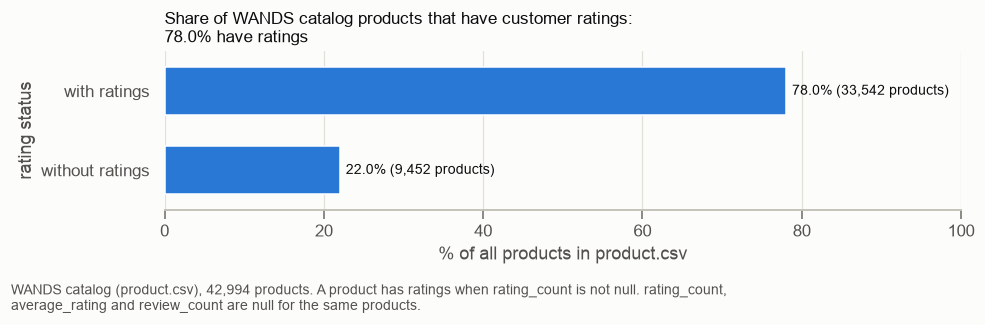

In [9]:
has_ratings = products["rating_count"].notna()
rating_presence = pd.DataFrame({
    "group": ["with ratings", "without ratings"],
    "products": [has_ratings.sum(), (~has_ratings).sum()],
})
rating_presence["pct"] = rating_presence["products"] / len(products) * 100
display(plots.table(rating_presence.set_index("group"), "Products with and without ratings in product.csv"))

fig, ax = plt.subplots(figsize=(9, 2.6))
sns.barplot(data=rating_presence, y="group", x="pct", color=plots.SERIES_1, saturation=1, width=0.6, ax=ax)
ax.bar_label(ax.containers[0], padding=4, color=plots.PRIMARY_INK, fontsize=9,
             labels=[f"{row.pct:.1f}% ({row.products:,} products)" for row in rating_presence.itertuples()])
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.set_title(f"Share of WANDS catalog products that have customer ratings:\n{rating_presence['pct'].iloc[0]:.1f}% have ratings")
ax.set_xlabel("% of all products in product.csv")
ax.set_ylabel("rating status")
fig.tight_layout()
plots.add_caption(fig, f"WANDS catalog (product.csv), {len(products):,} products. A product has ratings when rating_count "
                       "is not null. rating_count, average_rating and review_count are null for the same products.", width=115)
plt.show()

**Resultados**
- 33.542 produtos (78,0%) têm rating, e 9.452 (22,0%) não têm.

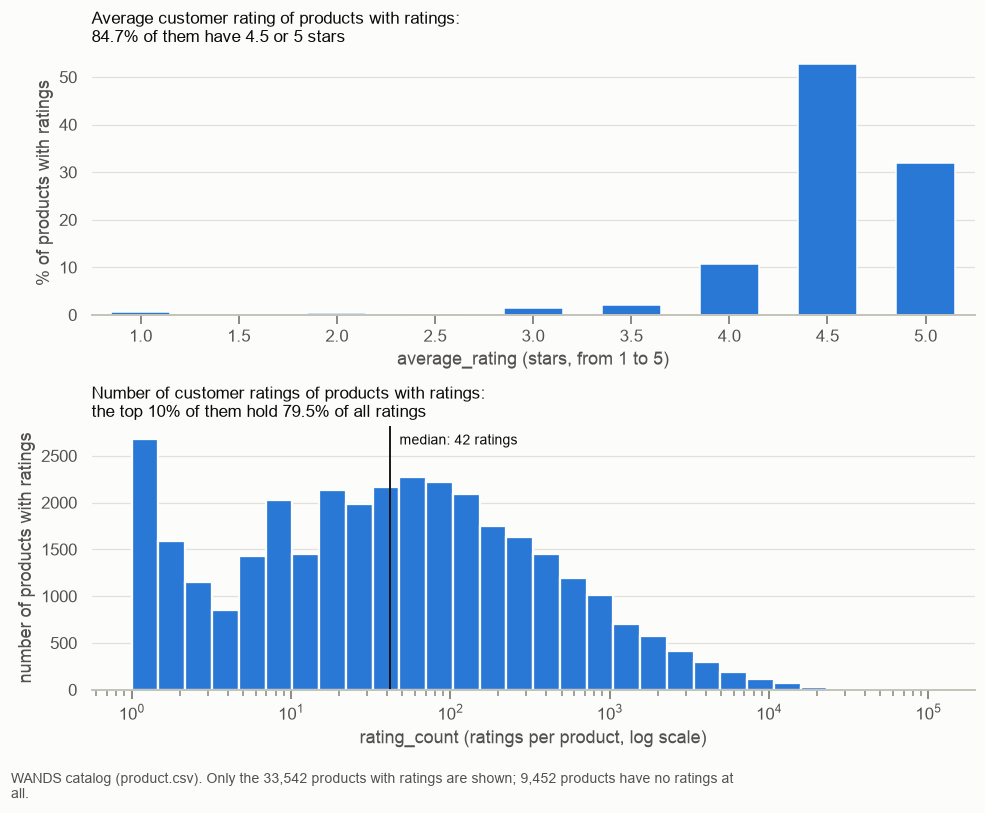

In [10]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7))

rating_share = rated_products["average_rating"].value_counts(normalize=True).sort_index() * 100
high_rating_share = rating_share[rating_share.index >= 4.5].sum()
sns.barplot(x=rating_share.index.astype(str), y=rating_share.values, color=plots.SERIES_1, saturation=1, width=0.6, ax=top)
top.grid(axis="x", visible=False)
top.set_title(f"Average customer rating of products with ratings:\n{high_rating_share:.1f}% of them have 4.5 or 5 stars")
top.set_xlabel("average_rating (stars, from 1 to 5)")
top.set_ylabel("% of products with ratings")

sns.histplot(rated_products["rating_count"], log_scale=True, bins=30, color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=bottom)
bottom.grid(axis="x", visible=False)
top_10pct_share = (rated_products["rating_count"].nlargest(round(len(rated_products) * 0.1)).sum()
                   / rated_products["rating_count"].sum() * 100)
bottom.set_title(f"Number of customer ratings of products with ratings:\nthe top 10% of them hold {top_10pct_share:.1f}% of all ratings")
bottom.set_xlabel("rating_count (ratings per product, log scale)")
bottom.set_ylabel("number of products with ratings")
plots.reference_line(bottom, rated_products["rating_count"].median(), f"median: {rated_products['rating_count'].median():.0f} ratings")

fig.tight_layout()
plots.add_caption(fig, f"WANDS catalog (product.csv). Only the {len(rated_products):,} products with ratings are shown; "
                       f"{len(products) - len(rated_products):,} products have no ratings at all.", width=115)
plt.show()

**Resultados**
- **Mesmos produtos:** `rating_count`, `average_rating` e `review_count` são null exatamente nos mesmos 9.452 produtos.
- **Sem zeros:** entre os produtos com rating, `rating_count` é sempre pelo menos 1. `review_count` é 0 em 543 produtos (clientes deram nota sem escrever review).
- **Escala:** `average_rating` vai de 1 a 5, em passos de 0,5. 84,7% dos produtos com rating têm 4,5 ou 5 estrelas, então a coluna distingue pouco os produtos.
- **Concentração:** em `rating_count`, a mediana é 42, a média é 430 e o máximo é 109.226. Os 10% de produtos com mais ratings concentram 79,5% de todos os ratings.
- **Coerência:** `review_count` nunca passa de `rating_count`.

**Suposições**
- **Null significa "nenhum cliente deu nota"**, e não dado perdido. O dataset não documenta isso. O que apoia a suposição: `rating_count` nunca é 0, então o zero parece estar representado pelo null. Se for dado perdido, uma feature `has_ratings` mediria falha de coleta, e não falta de ratings.

**Limitações**
- O dataset não tem datas, então não dá para dizer se os produtos sem rating são produtos novos.
- Esta seção descreve as colunas sozinhas. A relação com `label` é medida nas Etapas 4.7 e 4.8.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Criar a feature `has_ratings` (1 se o produto tem rating, 0 se não) e manter o null nas outras | proposta | imputar zero (confunde "sem rating" com nota baixa); imputar a mediana; deixar o modelo tratar o null, como fazem modelos de árvore |
| Aplicar log em `rating_count` e `review_count` | proposta | usar a posição do produto na ordenação (rank); não transformar, já que modelos de árvore só usam a ordem dos valores |
| Usar `average_rating` como está | proposta | ajustar a nota pelo número de ratings (média bayesiana), porque uma nota com poucos ratings é menos confiável |

#### O que isso muda para o ranking (nossa interpretação, não medida)

Só os números de `rating_count` vêm das saídas acima.

- **A escala pode atrapalhar.** Com mediana 42 e máximo 109.226, em valores brutos a diferença entre 42 e 100 ratings quase some. O log torna a diferença proporcional: ir de 10 para 100 pesa o mesmo que ir de 1.000 para 10.000. Isso importa para modelos sensíveis à escala, como regressão logística e redes neurais. Modelos de árvore, como LambdaMART, só usam a ordem dos valores e praticamente não mudam.
- **`average_rating` não é igualmente confiável em todos os produtos.** Um 5,0 com 2 ratings diz menos do que um 4,5 com 10.000. Por isso vale dar `average_rating` e `rating_count` juntos ao modelo.
- **Risco de favorecer produtos populares.** Se `rating_count` tiver peso alto, o modelo pode subir produtos populares mesmo quando outro atende melhor à query.

**O que fazer**
- **Ablation:** comparar o modelo de ranking com e sem as colunas de rating, como o desafio pede. Ablation é treinar o modelo sem um grupo de features e medir quanto a nota cai.
- **Error analysis:** conferir se os erros se concentram em produtos muito populares ou sem rating.
- **Lembrar o que `label` mede:** se o produto atende à query, e não se ele vende bem. Uma feature de popularidade que ajude pouco aqui ainda pode ser útil em produção, onde o objetivo também inclui vendas.

### 2.2 · `product_class` e `category_hierarchy`

As duas colunas categorizam o produto de formas diferentes:
- `product_class` pode ter mais de um valor, separados por `|`, como em `Sofas|Sectionals`. Chamamos cada parte de **single value** de `product_class`. As combinações inflam a contagem de 860 valores distintos da Etapa 1.3.
- `category_hierarchy` é uma sequência de **levels**, do mais geral ao mais específico, separados por ` / `, como em `Furniture / Living Room Furniture / Sofas`.

In [11]:
product_classes = products["product_class"].map(data.split_product_classes)
product_class_counts = product_classes.explode().dropna().value_counts()

display(plots.table(product_classes.str.len().value_counts().sort_index().rename_axis("single_values").to_frame("products"),
                    "Products by number of single product_class values",
                    note="0 means product_class is null."))
display(plots.table(pd.Series({
    "distinct raw values": products["product_class"].nunique(),
    "distinct single values": product_class_counts.size,
    "single values with 1 product": (product_class_counts == 1).sum(),
    "single values with fewer than 10 products": (product_class_counts < 10).sum(),
}, name="count"), "Distinct product_class values, before and after splitting on '|'"))
display(plots.table(product_class_counts.head(10).to_frame("products"),
                    "The 10 most common single product_class values"))

category_hierarchy_levels = products["category_hierarchy"].map(data.split_category_hierarchy)
display(plots.table(category_hierarchy_levels.str.len().value_counts().sort_index().rename_axis("levels").to_frame("products"),
                    "Products by number of levels in category_hierarchy",
                    note="0 means category_hierarchy is null."))
print(f"distinct first-level values: {category_hierarchy_levels.str[0].nunique()}")
plots.table(category_hierarchy_levels.str[0].value_counts(dropna=False).head(15).rename_axis("first_level").to_frame("products"),
            "The 15 most common first levels of category_hierarchy",
            note="NaN: category_hierarchy is null.")

,products
single_values,
0,"2,852"
1,"37,895"
2,"2,162"
3,81
4,4


,count
distinct raw values,860
distinct single values,601
single values with 1 product,98
single values with fewer than 10 products,273


,products
product_class,
Accent Chairs,"1,426"
Area Rugs,"1,320"
Beds,"1,261"
Coffee & Cocktail Tables,"1,138"
Floor & Wall Tile,862
Dining Chairs,803
Bar Stools,794
Desks,752
End Tables,746


,products
levels,
0,"1,556"
1,103
2,"1,720"
3,"16,297"
4,"16,256"
5,"6,453"
6,609


distinct first-level values: 55


,products
first_level,
Furniture,"16,039"
Home Improvement,"4,686"
Décor & Pillows,"4,612"
Outdoor,"3,394"
Storage & Organization,"2,175"
Lighting,"2,072"
Rugs,"2,002"
Bed & Bath,"1,865"
Kitchen & Tabletop,"1,615"


**Resultados em `product_class`**
- Os 860 valores distintos são, na verdade, 601 single values: 2.247 produtos têm mais de um single value.
- A distribuição é desigual: 273 single values têm menos de 10 produtos, e 98 têm um só.

**Resultados em `category_hierarchy`**
- 90,7% dos produtos têm de 3 a 5 levels.
- O primeiro level tem 55 valores distintos, mas é concentrado: Furniture tem 16.039 produtos (37,3% do catalog).

**Suposições**
- **O `|` separa categorias independentes, e o produto pertence a todas elas.** Se a combinação fosse uma categoria própria, deveríamos comparar a combinação inteira, e não cada single value.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Separar `product_class` em single values | decidida (`data.split_product_classes`) | tratar cada combinação como um valor (860 valores); usar só o primeiro single value |

### 2.3 · Dá para deduzir `product_class` de `category_hierarchy`, e vice-versa?

Na Etapa 1.3, `product_class` era null em 6,63% dos produtos, e `category_hierarchy` em 3,62%. Se uma coluna previsse bem a outra, poderíamos preencher parte desses nulls.

Medimos duas coisas:
1. Quantos produtos têm uma coluna e não a outra, porque só esses poderiam ser preenchidos.
2. O **modal share**: agrupamos os produtos pelo valor de uma coluna e medimos a fração que tem o valor mais comum (a moda) da outra coluna no seu grupo. Exemplo: se 10 produtos têm o mesmo `category_hierarchy` e 9 deles têm `product_class` = `Sofas`, o modal share desse grupo é 0,9. Quanto mais perto de 1, melhor a dedução funcionaria.

In [12]:
def modal_share(df: pd.DataFrame, by: str, target: str) -> float:
    """Share of rows whose target equals the most common target within their ``by`` group."""
    known = df.dropna(subset=[by, target])
    return known.groupby(by)[target].agg(lambda s: s.value_counts().iloc[0]).sum() / len(known)


has_product_class = products["product_class"].notna()
has_category_hierarchy = products["category_hierarchy"].notna()
display(plots.table(pd.Series({
    "product_class null, category_hierarchy present": (~has_product_class & has_category_hierarchy).sum(),
    "category_hierarchy null, product_class present": (has_product_class & ~has_category_hierarchy).sum(),
    "both null": (~has_product_class & ~has_category_hierarchy).sum(),
}, name="products"), "Products where one category column is null"))

plots.table(pd.DataFrame({
    "group_column": ["category_hierarchy", "product_class"],
    "predicted_column": ["product_class", "category_hierarchy"],
    "modal_share": [modal_share(products, "category_hierarchy", "product_class"),
                    modal_share(products, "product_class", "category_hierarchy")],
}).set_index("group_column"), "Modal share: how well one category column predicts the other",
    note="Share of products, among those with both columns, whose predicted_column equals the most common value of their group.",
    precision=3)

,products
"product_class null, category_hierarchy present","2,691"
"category_hierarchy null, product_class present","1,395"
both null,161


,predicted_column,modal_share
group_column,,
category_hierarchy,product_class,0.947
product_class,category_hierarchy,0.765


**Resultados**
- **Só parte dos nulls poderia ser preenchida:** 2.691 produtos têm `category_hierarchy` sem `product_class`, 1.395 têm `product_class` sem `category_hierarchy`, e 161 não têm nenhuma das duas.
- **`category_hierarchy` prevê bem `product_class`:** modal share de 0,947. O contrário funciona pior: 0,765.

**Suposições**
- **Deixar a coluna vazia prejudica pouco a busca**, porque esses produtos ainda têm `product_name` e `product_features`. Ainda não medimos isso; a error analysis do retrieval pode mostrar o contrário.

**Limitações**
- O modal share é otimista: é medido nos mesmos produtos usados para calcular a moda, e grupos com poucos produtos acertam quase por definição. A Etapa 2.3.1 mede o erro em produtos separados.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Não preencher os nulls por enquanto | proposta | preencher com a moda do grupo (medido aqui); treinar um classificador a partir do texto do produto; criar o valor explícito "unknown" |

#### 2.3.1 · Quanto erraria a mode imputation?

**Termos**
- **Mode imputation:** preencher um null com o valor mais comum (a moda) entre os produtos do mesmo grupo. Um grupo são os produtos com o mesmo texto na coluna usada para agrupar.
- **Training set e held-out set:** separamos os produtos que têm as duas colunas em 80% (training set, usado para calcular a moda de cada grupo) e 20% (held-out set, em que escondemos o valor verdadeiro para medir o erro). Esses sets são de produtos e só existem nesta medição; não têm relação com o split de queries da Etapa 4.6.
- **In-sample error:** % de produtos cujo valor difere da moda do grupo, medido nos mesmos produtos usados para calcular a moda. É 1 − modal share da Etapa 2.3.
- **Held-out error:** % de produtos do held-out set que receberiam o valor errado.
- **Imputation coverage:** % de produtos do held-out set cujo grupo existe no training set e que, portanto, podem ser preenchidos.

**O que fazemos:** repetimos o sorteio 80/20 com 5 seeds (0 a 4) e tiramos a média. A medição é uma contagem sobre textos idênticos; não usa LLM nem o significado das palavras.

**Colunas da tabela**
- `imputed_column`: a coluna preenchida; `group_column`: a coluna usada para agrupar.
- `in_sample_error_pct`, `held_out_error_pct`, `imputation_coverage_pct`: as medidas definidas acima, as duas últimas na média das 5 seeds.
- `null_products`: produtos com `imputed_column` null e `group_column` preenchida.
- `imputable_products`: desses, quantos têm um grupo que existe entre os produtos com as duas colunas.
- `estimated_wrong_imputations`: `imputable_products` × `held_out_error_pct`.

In [13]:
IMPUTATION_SEEDS = range(5)
IMPUTATION_TRAIN_FRACTION = 0.8


def held_out_mode_imputation(df: pd.DataFrame, by: str, target: str, seed: int) -> dict[str, float]:
    """Compute the mode per group on a training set and score the imputation on a held-out set."""
    known = df.dropna(subset=[by, target]).sample(frac=1, random_state=seed)
    n_train = int(len(known) * IMPUTATION_TRAIN_FRACTION)
    training_set, held_out_set = known.iloc[:n_train], known.iloc[n_train:]
    mode_by_group = training_set.groupby(by)[target].agg(lambda s: s.value_counts().index[0])
    imputed = held_out_set[by].map(mode_by_group)
    has_group = imputed.notna()
    return {
        "coverage_pct": has_group.mean() * 100,
        "error_pct": (imputed[has_group] != held_out_set.loc[has_group, target]).mean() * 100,
    }


imputation_results = []
for by, target in [("category_hierarchy", "product_class"), ("product_class", "category_hierarchy")]:
    runs = pd.DataFrame([held_out_mode_imputation(products, by, target, seed) for seed in IMPUTATION_SEEDS])
    known_groups = products.dropna(subset=[by, target])[by].unique()
    null_products = products[products[target].isna() & products[by].notna()]
    imputable_products = null_products[by].isin(known_groups).sum()
    held_out_error = runs["error_pct"].mean()
    imputation_results.append({
        "imputed_column": target,
        "group_column": by,
        "in_sample_error_pct": (1 - modal_share(products, by, target)) * 100,
        "held_out_error_pct": held_out_error,
        "imputation_coverage_pct": runs["coverage_pct"].mean(),
        "null_products": len(null_products),
        "imputable_products": imputable_products,
        "estimated_wrong_imputations": imputable_products * held_out_error / 100,
    })
plots.table(pd.DataFrame(imputation_results).set_index("imputed_column"),
            "Mode imputation of product_class and category_hierarchy: error and expected wrong values",
            note=f"80/20 split of the products with both columns, mean of {len(IMPUTATION_SEEDS)} seeds (0 to 4).")

,group_column,in_sample_error_pct,held_out_error_pct,imputation_coverage_pct,null_products,imputable_products,estimated_wrong_imputations
imputed_column,,,,,,,
product_class,category_hierarchy,5.3,5.9,98.5,"2,691","2,672",156.6
category_hierarchy,product_class,23.5,24.3,99.4,"1,395","1,380",335.2


**Resultados**
- **O held-out error fica perto do in-sample error:** 5,9% contra 5,3% ao preencher `product_class`, e 24,3% contra 23,5% ao preencher `category_hierarchy`.
- **A imputation geraria valores errados:** cerca de 157 dos 2.672 produtos preenchíveis em `product_class` e cerca de 335 dos 1.380 em `category_hierarchy`.
- **Preencher `category_hierarchy` é o caso mais arriscado:** o erro é maior, e um erro coloca vários levels de texto possivelmente errados no indexed text.

**O que um erro causaria (nossa interpretação, não medida)**

Exemplo inventado: o produto "Leather Recliner", sem `product_class`, recebe `Couches`, porque essa é a moda do seu `category_hierarchy`.
- **Retrieval:** a query "couch" passa a trazer esse produto. A query "recliner" já o encontrava pelo `product_name`, então a imputation só acrescenta um erro.
- **Ranking:** uma feature que compara a query com `product_class` recebe um valor errado, com a mesma aparência de um valor real.
- **Error analysis:** o valor preenchido parece original, a menos que se guarde quais valores foram preenchidos.

Deixar vazio custa menos: o produto perde um reforço de texto, mas continua encontrável por `product_name` e `product_features`.

**Suposições**
- **Em produção, `product_class` e `category_hierarchy` também podem ser null.** O dataset não confirma isso. Se em produção todo produto tivesse as duas colunas, o modelo aprenderia com nulls que não vão existir. Nesse caso, valeria preencher os dados de treino e avaliação (mais para `product_class` do que para `category_hierarchy`) ou tirar os produtos com null do treino do ranking.
- **Os produtos com null erram na mesma taxa** dos produtos com as duas colunas. Não dá para testar, porque o valor correto deles é desconhecido.

**Limitações**
- Erro significa texto diferente. `Sofas` e `Sofas|Sectionals` contam como erro, então a taxa pode exagerar o problema.
- `estimated_wrong_imputations` aplica o held-out error a grupos calculados com todos os produtos que têm as duas colunas, e não só com o training set.

**Escolhas e alternativas**

| Escolha | Status | Alternativas, na ordem em que testaríamos |
|---|---|---|
| Manter os nulls vazios; testar outra opção só se a error analysis mostrar produtos relevantes perdidos por causa deles | proposta | preencher `product_class` só quando `product_name` contém o valor sugerido (bloquearia o exemplo acima, mas preencheria menos produtos); prever `product_class` com um classificador sobre `product_name` e `product_features`, só com confiança alta; guardar o valor preenchido em um campo separado, com peso menor no retrieval |

### 2.4 · `product_name` e `product_description`

São os principais textos do produto para a busca. Medimos:
1. O tamanho de cada texto, em palavras separadas por espaço (não em tokens).
2. Quantos produtos repetem o `product_name` de outro.
3. Se os 6.008 produtos sem `product_description` (Etapa 1.3) têm as outras colunas de texto.

In [14]:
product_name_words = products["product_name"].str.split().str.len()
product_description_words = products["product_description"].str.split().str.len()
display(plots.table(pd.DataFrame({"product_name_words": product_name_words,
                                  "product_description_words": product_description_words})
                    .describe(percentiles=[0.5, 0.9, 0.99]),
                    "Length of product_name and product_description, in words",
                    note="Words: whitespace-separated pieces of the text. product_description is counted only where it is not null."))

shares_product_name = products["product_name"].duplicated(keep=False)
print(f"products whose product_name is identical to another product's: {shares_product_name.sum():,}")
display(plots.table(products.loc[shares_product_name, "product_name"].value_counts().head(5).to_frame("products"),
                    "The 5 most repeated product_name values"))

products_without_description = products[products["product_description"].isna()]
display(plots.table((products_without_description[["product_name", "product_class", "category_hierarchy", "product_features"]]
                     .notna().mean() * 100).to_frame("pct_not_null"),
                    f"Other columns among the {len(products_without_description):,} products without product_description",
                    note="% of these products where the column is not null."))

feature_pairs_per_product = products["product_features"].map(data.parse_product_features).str.len()
plots.table(pd.Series({
    "with product_description": feature_pairs_per_product[products["product_description"].notna()].median(),
    "without product_description": feature_pairs_per_product[products["product_description"].isna()].median(),
}, name="median_key_value_pairs"), "Median number of key:value pairs in product_features",
    note="A key:value pair is one item of product_features, such as mattresssize:twin (Etapa 2.5).", precision=0)

,product_name_words,product_description_words
count,"42,994.0","36,986.0"
mean,6.8,83.0
std,3.8,54.8
min,1.0,1.0
50%,6.0,76.0
90%,11.0,142.0
99%,20.0,295.0
max,49.0,791.0


products whose product_name is identical to another product's: 768


,products
product_name,
indoor/outdoor seat/back cushion,6
coffee table,5
indoor/outdoor dining chair cushion,5
storage cabinet,5
wall shelf,5


,pct_not_null
product_name,100.0
product_class,92.8
category_hierarchy,96.4
product_features,100.0


,median_key_value_pairs
with product_description,55
without product_description,47


**Resultados**
- **Os produtos sem `product_description` continuam com texto:** todos os 6.008 têm `product_name` e `product_features`, com 47 pares `key:value` na mediana, contra 55 dos demais.
- **`product_name` é curto e `product_description` é longo:** mediana de 6 e 76 palavras.
- **`product_name` nem sempre distingue um produto:** 768 produtos têm o mesmo `product_name` de outro, e os nomes repetidos são genéricos, como "coffee table".

**Suposições**
- **Esses produtos continuam encontráveis** se o retrieval indexar `product_name` e `product_features`. A escolha do indexed text está no notebook `02_bm25.ipynb`.

**Limitações**
- Palavras separadas por espaço contam pontuação solta, como `,`, como palavra. Os tamanhos são aproximados.

### 2.5 · `product_features`

**Termos**
- **Par `key:value`** (*key:value pair*): cada item de `product_features`; os itens são separados por `|`. Em `mattresssize:twin`, a **key** é `mattresssize` e o **value** é `twin`.
- **Variant:** versão do mesmo produto que muda em algum atributo, como a mesma cama em vários tamanhos.
- Apesar do nome, `product_features` não contém features no sentido do ranking (números que descrevem um par query-produto). Contém pares `key:value`, que podem ou não dar origem a uma feature.

**Perguntas**
1. Quantos pares `key:value` cada produto tem?
2. Quais keys são comuns? São candidatas a entrar no indexed text.
3. A mesma key aparece com values diferentes no mesmo produto? Isso sugeriria variants.

In [15]:
key_value_pairs = products["product_features"].map(data.parse_product_features)
feature_pairs = (
    pd.DataFrame({"product_id": products["product_id"], "key_value_pair": key_value_pairs})
    .explode("key_value_pair")
    .dropna(subset="key_value_pair")
)
feature_pairs["key"] = feature_pairs["key_value_pair"].str[0]
feature_pairs["value"] = feature_pairs["key_value_pair"].str[1]

display(plots.table(key_value_pairs.str.len().describe(percentiles=[0.5, 0.9, 0.99]).to_frame("key_value_pairs").T,
                    "Number of key:value pairs per product in product_features"))

values_per_product_key = feature_pairs.groupby(["product_id", "key"])["value"].agg(["size", "nunique"])
display(plots.table(pd.Series({
    "distinct keys in the catalog": feature_pairs["key"].nunique(),
    "products with a key that appears more than once": values_per_product_key[values_per_product_key["size"] > 1]
        .index.get_level_values("product_id").nunique(),
    "products with a key that has different values": values_per_product_key[values_per_product_key["nunique"] > 1]
        .index.get_level_values("product_id").nunique(),
}, name="count"), "Keys of product_features, and keys repeated inside a product"))

key_product_share = feature_pairs.groupby("key")["product_id"].nunique() / len(products) * 100
plots.table(key_product_share.sort_values(ascending=False).head(20).to_frame("pct_of_products"),
            "The 20 most common keys in product_features",
            note="% of all catalog products that have the key at least once.")

,count,mean,std,min,50%,90%,99%,max
key_value_pairs,"42,994.0",55.4,24.6,0.0,54.0,88.0,120.0,402.0


,count
distinct keys in the catalog,"7,961"
products with a key that appears more than once,"29,557"
products with a key that has different values,"29,547"


,pct_of_products
key,
overallproductweight,92.6
countryoforigin,79.1
supplierintendedandapproveduse,75.6
overallheight-toptobottom,73.6
overallwidth-sidetoside,73.0
commercialwarranty,71.0
productwarranty,67.9
overalldepth-fronttoback,64.5
purposefuldistressingtype,61.2


**Resultados**
- **Muitos pares e muitas keys:** cada produto tem 54 pares `key:value` na mediana (o mínimo é 0), e há 7.961 keys distintas no catalog.
- **As keys mais comuns parecem pouco úteis para a busca:** peso (`overallproductweight`), país de origem (`countryoforigin`) e garantia (`commercialwarranty`, `productwarranty`). Quais keys entram no indexed text é decidido no notebook `02_bm25.ipynb`.
- **Keys com values diferentes no mesmo produto são comuns:** 29.547 produtos (68,7%). O produto 0, por exemplo, tem `overallwidth-sidetoside` = 64,7 e 43,3 e `mattresssize` = twin e queen.

**O que isso implica**
- No indexed text, vários values ajudam: o produto 0 pode ser encontrado por "twin" e por "queen".
- Numa feature numérica do ranking, vários values atrapalham: a feature precisa de um número por produto, e escolher o primeiro, o menor, o maior ou a média descreve só parte do produto.

**Suposições**
- **Uma key com values diferentes indica variants do produto.** Se não for, a key pode ter vários values legítimos, como os usos aprovados em `supplierintendedandapproveduse`, e a contagem de 29.547 superestima as variants. A Etapa 2.5.1 testa essa hipótese com keys de tamanho e cor.
- **Trechos de `product_features` sem `:` são restos de um `|` dentro de um value**, por isso `data.parse_product_features` os descarta. Se forem pares mal formados, perdemos texto desses produtos.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Descartar os trechos sem `:` | decidida (`data.parse_product_features`) | juntá-los ao value do par anterior |
| Quais keys entram no indexed text | em aberto | todas as keys e values; só os values; uma lista feita à mão; escolher pelo ganho na validation; nenhuma |
| Como usar keys numéricas com vários values | em aberto | descartar; usar mínimo e máximo; usar o primeiro value |

#### 2.5.1 · Um `product_id` reúne vários SKUs?

**Termos**
- **SKU** (*stock keeping unit*): cada versão vendável de um produto. A mesma cama nos tamanhos queen e king são dois SKUs.
- **Parent product:** a página que reúne as opções de um produto. Pode incluir vários SKUs.

Um catalog pode dar um id para cada SKU ou um id para cada parent product. O dataset não documenta o que `product_id` representa. Testamos dois sinais:
1. O mesmo `product_id` lista vários tamanhos ou cores? Usamos as **variant keys** `mattresssize`, `rugsize`, `size`, `finish` e `color`, e comparamos os values em minúsculas.
2. `product_id` diferentes têm o mesmo texto? Se cada SKU tivesse um id, esperaríamos muitos produtos com o mesmo `product_name` e `product_description`, mudando só o tamanho em `product_features`.

In [16]:
VARIANT_KEYS = ["mattresssize", "rugsize", "size", "finish", "color"]

lowercase_feature_pairs = feature_pairs.assign(value=feature_pairs["value"].str.lower())
variant_values = (
    lowercase_feature_pairs[lowercase_feature_pairs["key"].isin(VARIANT_KEYS)]
    .groupby(["key", "product_id"])["value"]
    .agg(lambda s: sorted(set(s)))
)
n_variant_values = variant_values.str.len()
several_values = pd.DataFrame({
    "products_with_key": n_variant_values.groupby("key").size(),
    "products_with_several_values": (n_variant_values > 1).groupby("key").sum(),
}).loc[VARIANT_KEYS]
several_values["pct_with_several_values"] = several_values["products_with_several_values"] / several_values["products_with_key"] * 100
display(plots.table(several_values, "Products that list more than one value for a variant key",
                    note="Values are compared in lowercase. A product has several values when the key appears with at least two different values."))

mattresssize_values = variant_values.loc["mattresssize"]
print(f"products with both queen and king in mattresssize: {mattresssize_values.map(lambda values: {'queen', 'king'} <= set(values)).sum():,}")
print(f"product 0, mattresssize values: {mattresssize_values.loc[0]}")

shared_text = []
for columns in (["product_name"], ["product_name", "product_description"]):
    complete = products.dropna(subset=columns)
    sharing = complete[complete.duplicated(columns, keep=False)]
    shared_text.append({
        "identical_columns": " + ".join(columns),
        "products": len(sharing),
        "pct_of_catalog": len(sharing) / len(products) * 100,
        "groups": sharing.groupby(columns).ngroups,
        "groups_with_identical_product_features": sharing[sharing.duplicated([*columns, "product_features"], keep=False)].groupby(columns).ngroups,
        "products_with_mattresssize": sharing["product_id"].isin(mattresssize_values.index).sum(),
    })
plots.table(pd.DataFrame(shared_text).set_index("identical_columns"),
            "Products with a different product_id but identical text",
            note="A group is a set of products with the same values in identical_columns.")

,products_with_key,products_with_several_values,pct_with_several_values
key,,,
mattresssize,"1,790","1,186",66.3
rugsize,624,395,63.3
size,673,264,39.2
finish,"4,914","1,071",21.8
color,"15,214","3,218",21.2


products with both queen and king in mattresssize: 863
product 0, mattresssize values: ['queen', 'twin']


,products,pct_of_catalog,groups,groups_with_identical_product_features,products_with_mattresssize
identical_columns,,,,,
product_name,768,1.8,351,0,40
product_name + product_description,46,0.1,23,0,0


**Resultados**
- **Um `product_id` parece reunir vários SKUs.** Dos produtos com `mattresssize`, 66,3% têm mais de um value, e 863 têm `queen` e `king` no mesmo `product_id`. `rugsize` (63,3%), `size` (39,2%), `finish` (21,8%) e `color` (21,2%) seguem o mesmo padrão.
- **`product_id` diferentes raramente têm o mesmo texto:** só 46 produtos (0,1% do catalog), em 23 grupos, têm `product_name` e `product_description` iguais. Nenhum desses grupos tem `product_features` idêntico, e nenhum desses produtos tem `mattresssize`. Ou seja, não há sinal de queen e king em ids separados.

**Suposições**
- **Vários values numa variant key indicam SKUs diferentes.** O dataset não confirma isso. Uma key pode ter vários values por outro motivo, como uma cor de estrutura e outra de estofado.

#### 2.5.2 · `product_name` diz de qual SKU se trata?

Se um `product_id` reúne vários SKUs (Etapa 2.5.1), o `label` pode ter sido dado pensando em um deles. Para saber se o nome indica qual, procuramos cada value das variant keys em `product_name`, nos produtos com vários values. A busca exige o texto exato do value, sem fazer parte de uma palavra maior (`queen` não casa com `queens`).

In [17]:
def count_values_in_name(values: list[str], name: str) -> int:
    """Count how many values appear in the name as an exact text match, outside longer words."""
    return sum(re.search(rf"(?<![a-z0-9]){re.escape(value)}(?![a-z0-9])", name) is not None for value in values)


lowercase_product_names = products.set_index("product_id")["product_name"].fillna("").str.lower()

values_in_name = []
for key in VARIANT_KEYS:
    product_values = variant_values.loc[key]
    with_several = product_values[product_values.str.len() > 1]
    mentions = pd.Series([count_values_in_name(values, lowercase_product_names[product_id])
                          for product_id, values in with_several.items()])
    values_in_name.append({
        "key": key,
        "products_with_several_values": len(with_several),
        "none_in_name_pct": (mentions == 0).mean() * 100,
        "exactly_one_in_name_pct": (mentions == 1).mean() * 100,
        "two_or_more_in_name_pct": (mentions >= 2).mean() * 100,
    })
display(plots.table(pd.DataFrame(values_in_name).set_index("key"),
                    "Products with several values in a variant key: how many of the values appear in product_name",
                    note="Exact text match in lowercase, outside longer words."))

single_mattresssize = mattresssize_values[mattresssize_values.str.len() == 1]
single_in_name = sum(count_values_in_name(values, lowercase_product_names[product_id]) > 0
                     for product_id, values in single_mattresssize.items())
print(f"products with a single mattresssize value: {len(single_mattresssize):,}; "
      f"value found in product_name: {single_in_name:,} ({single_in_name / len(single_mattresssize) * 100:.1f}%)")

,products_with_several_values,none_in_name_pct,exactly_one_in_name_pct,two_or_more_in_name_pct
key,,,,
mattresssize,"1,186",98.1,1.9,0.1
rugsize,395,100.0,0.0,0.0
size,264,99.6,0.0,0.4
finish,"1,071",98.2,1.4,0.4
color,"3,218",98.7,1.3,0.0


products with a single mattresssize value: 604; value found in product_name: 442 (73.2%)


**Resultados**
- **`product_name` quase nunca indica o SKU:** nos produtos com vários values, nenhum aparece no nome em 98,1% dos casos de `mattresssize`, 100,0% de `rugsize`, 99,6% de `size`, 98,2% de `finish` e 98,7% de `color`. O produto 0, por exemplo, se chama `solid wood platform bed` e lista `queen` e `twin`.
- **O nome cita o tamanho quando só há um:** entre os 604 produtos com um único value em `mattresssize`, ele aparece no nome em 442 (73,2%). Com vários values, ao menos um aparece no nome em só 2,0%. Isso é coerente com um `product_id` por parent product, mas não prova esse modelo.

**O que isso implica (nossa interpretação, não medida)**
- **`label` vale para o `product_id` inteiro:** não sabemos qual SKU o anotador considerou. Um produto com `queen` e `king` pode ser Exact para "king bed".
- **`product_features` é a principal fonte de tamanho e cor:** um retrieval que indexe só `product_name` pode não encontrar esse produto para "queen bed". Isso reforça incluir `product_features` no indexed text.
- **Features numéricas continuam ambíguas:** nada indica qual SKU corresponde a cada value de `overallwidth-sidetoside`.

**Suposições**
- **`product_name` descreve o parent product quando há vários SKUs.** O dataset não documenta isso.

**Limitações**
- A comparação exige o texto exato, então parte da ausência pode vir do formato: `full / double` não casa com "full". Em `rugsize`, não conferimos como value e nome são escritos.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Comparar values e nome por texto exato | decidida, nesta análise | comparar por tokens, o que casaria `full / double` com "full"; normalizar os formatos de tamanho antes; usar um modelo de extração de atributos |
| `product_id` é a unidade de retrieval e de avaliação, porque `label` é dado nesse nível | decidida | um documento por SKU, o que exigiria ligar os values entre si, informação que o dataset não tem |

## Etapa 3 · `query.csv`

### 3.1 · Queries com `query_class` null e formato de `query`

Na Etapa 1.3, 6 queries tinham `query_class` null; aqui vemos quais são. Também medimos o tamanho e o formato de `query`, porque query e produto precisam passar pelo mesmo processamento de texto para os tokens casarem.

In [18]:
display(plots.table(queries[queries["query_class"].isna()].set_index("query_id"),
                    "Queries with a null query_class"))

query_words = queries["query"].str.split().str.len()
display(plots.table(query_words.value_counts().sort_index().rename_axis("words").to_frame("queries"),
                    f"Length of the {len(queries)} queries, in words",
                    note="Words: whitespace-separated pieces of the text."))

has_special_character = queries["query"].str.contains(r"[^a-zA-Z0-9 ]")
print(f"queries with an uppercase character: {(queries['query'] != queries['query'].str.lower()).sum()}")
print(f"queries with a character that is not a letter, digit or space: {has_special_character.sum()}")
plots.table(queries.loc[has_special_character, ["query_id", "query"]].set_index("query_id"),
            "Queries with a character that is not a letter, digit or space")

,query,query_class
query_id,,
197,desk for kids tjat ate 10 year old,null
207,dull bed with shirt head board,null
218,wand bunk beds,null
219,trinaic towel rod,null
222,small loving roomtables,null
224,twin over full bunk beds cool desins,null


,queries
words,
1,23
2,109
3,169
4,99
5,41
6,16
7,11
8,8
9,3


queries with an uppercase character: 0
queries with a character that is not a letter, digit or space: 15


,query
query_id,
30,3 1/2 inch drawer pull
64,zachary 72.5
85,3/4 size mattress
181,e12/candelabra
188,"bedroom wall decor floral, multicolored with some teal (prints)"
203,ge top loading washer 4.5
208,"fawkes 36"" blue vanity"
223,wisdom stone river 3-3/4
238,outdoor seat/back cushion


**Resultados**
- **As 6 queries com `query_class` null parecem ter typos ou texto truncado** (nossa leitura): "tjat", "desins", "roomtables", "shirt head board".
- **Há typos no dataset.** Uma lexical search não encontra "desins" em produtos com "designs". As diretrizes de anotação mandam ignorar typos ao julgar, então essas queries podem ter produtos relevantes sem nenhum token em comum.
- **As queries são curtas:** 62,7% têm até 3 palavras, e 91,9% têm até 5.
- **`query` já está toda em minúsculas.**
- **15 queries têm caracteres especiais**, como `3 1/2`, `72.5`, `e12/candelabra` e `36"`. `product_name` escreve polegadas como `18 ''`, então `36"` pode não casar com o texto do produto. A Etapa 5.2 trata isso.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Não tratar typos agora; observar na error analysis | proposta | corrigir a ortografia da query (spelling correction); indexar pedaços de palavras (character n-grams); usar semantic search |

### 3.2 · Os valores de `query_class` existem em `product_class`?

Na Etapa 1.3, `product_class` tinha 860 valores distintos e `query_class`, 188. Aqui comparamos os dois conjuntos de valores, exigindo texto idêntico, de duas formas: com os valores brutos de `product_class` e com os single values (depois de separar por `|`, Etapa 2.2).

`query_class` é usada só para analisar os dados, nunca como entrada do sistema de busca, porque em produção a query chega sem categoria (`docs/EVALUATION.md`).

In [19]:
query_class_values = set(queries["query_class"].dropna())
raw_product_class_values = set(products["product_class"].dropna())
single_product_class_values = set(product_class_counts.index)
missing_query_class_values = sorted(query_class_values - single_product_class_values)

display(plots.table(pd.Series({
    "distinct query_class values": len(query_class_values),
    "query_class values containing '|'": sum("|" in value for value in query_class_values),
    "found among raw product_class values": len(query_class_values & raw_product_class_values),
    "found among single product_class values": len(query_class_values & single_product_class_values),
    "not found among single product_class values": len(missing_query_class_values),
    "single product_class values that are no query_class": len(single_product_class_values - query_class_values),
}, name="count"), "query_class values vs product_class values (identical text)"))
print("query_class values not found:", missing_query_class_values)

products_per_query_class = product_class_counts.reindex(sorted(query_class_values)).fillna(0).astype(int)
plots.table(products_per_query_class.describe(percentiles=[0.1, 0.5, 0.9]).to_frame("products").T,
            "Number of catalog products whose single product_class values include each query_class value")

,count
distinct query_class values,188
query_class values containing '|',0
found among raw product_class values,182
found among single product_class values,183
not found among single product_class values,5
single product_class values that are no query_class,418


query_class values not found: ['Crock Pots & Slow Cookers', 'Door Mats', 'Flatware Serving Pieces', 'Free Weights', 'Uniters Outdoor Furniture']


,count,mean,std,min,10%,50%,90%,max
products,188.0,195.8,242.0,0.0,24.4,109.0,511.3,"1,426.0"


**Resultados**
- **Quase todos os valores coincidem:** 183 dos 188 valores de `query_class` existem entre os single values de `product_class`. Com os valores brutos, seriam 182, então separar por `|` muda pouco aqui.
- **5 valores de `query_class` não existem em `product_class`:** `Crock Pots & Slow Cookers`, `Door Mats`, `Flatware Serving Pieces`, `Free Weights` e `Uniters Outdoor Furniture`. Podem ser nomes diferentes para o mesmo tipo de produto; não verificamos.
- **As queries cobrem só parte do catalog:** 418 dos 601 single values de `product_class` não são `query_class` de nenhuma query.

**Limitações**
- A comparação exige texto idêntico. Valores com grafia diferente contam como ausentes.

**Fonte externa:** `query_class` parece vir de um modelo de query classification (a Tabela 1 do [artigo](https://easychair.org/publications/preprint/wm4R) fala em "Predicted Class"), mas o artigo não afirma isso sobre a coluna.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Comparar valores com texto idêntico | decidida, nesta análise | normalizar o texto antes de comparar; comparar por similaridade de texto; mapear os valores à mão |

### 3.3 · Dá para fazer stratification do split por `query_class`?

**Stratification** é dividir as queries mantendo a mesma proporção de cada grupo nos três sets do split (train, validation e test set). Para estratificar por `query_class`, cada valor precisa de pelo menos 3 queries, uma por set.

In [20]:
queries_per_query_class = queries["query_class"].value_counts()

display(plots.table(queries_per_query_class.describe(percentiles=[0.5, 0.9]).to_frame("queries_per_query_class_value").T,
                    "Number of queries per query_class value"))
display(plots.table(pd.Series({
    "query_class values with 1 query": (queries_per_query_class == 1).sum(),
    "query_class values with fewer than 3 queries": (queries_per_query_class < 3).sum(),
}, name="values"), "query_class values too small for a 3-way stratified split"))
plots.table(queries_per_query_class.head(10).to_frame("queries"), "The 10 query_class values with the most queries")

,count,mean,std,min,50%,90%,max
queries_per_query_class_value,188.0,2.5,2.9,1.0,1.0,6.0,20.0


,values
query_class values with 1 query,98
query_class values with fewer than 3 queries,139


,queries
query_class,
Wall Art,20
Accent Chairs,16
Beds,15
Area Rugs,15
Coffee & Cocktail Tables,10
Dressers & Chests,10
Desks,9
Accent Pillows,8
Wall Décor,8


**Resultados**
- **Não dá para estratificar por `query_class`:** 139 dos 188 valores (73,9%) têm menos de 3 queries, e 98 têm uma só.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Não estratificar por `query_class`; o split adotado, por `exact_share` e `n_judged`, está na Etapa 4.6 | decidida | juntar os valores raros em "other"; estratificar pelo primeiro level de `category_hierarchy` |

### 3.4 · Há queries quase iguais?

Se "salon chair" ficar no train set e "salon chairs" no test set, o modelo já terá visto quase a mesma busca, e a nota no test set sai melhor do que deveria. Isso é um caso de data leakage.

Para encontrar queries quase iguais, calculamos uma **group key** para cada query (`profiling.query_group_key`): tokens no singular, em ordem alfabética. Queries com a mesma group key são quase iguais. Exemplo: "leather chairs" e "leather chair" viram as duas `chair leather`. A regra só pega diferenças de caixa, de ordem das palavras e de plural.

In [21]:
query_group_keys = queries["query"].map(profiling.query_group_key)
queries_per_group_key = query_group_keys.map(query_group_keys.value_counts())
near_duplicate_queries = queries.assign(group_key=query_group_keys)[queries_per_group_key > 1].sort_values("group_key")

print(f"distinct group keys among {len(queries)} queries: {query_group_keys.nunique()}")
plots.table(near_duplicate_queries.set_index("query_id"), "Near-duplicate queries: queries that share a group key")

distinct group keys among 480 queries: 479


,query,query_class,group_key
query_id,,,
26,leather chairs,Accent Chairs,chair leather
151,leather chair,Accent Chairs,chair leather


**Resultados**
- **Só um par de queries quase iguais:** "leather chair" (`query_id` 151) e "leather chairs" (`query_id` 26).

**Limitações**
- A regra não detecta sinônimos nem typos, então pode haver queries parecidas que ela não encontra.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Manter as queries quase iguais no mesmo set do split | decidida (`split.split_queries`) | remover uma delas; não tratar, porque o impacto é pequeno; ampliar a regra com similaridade de texto ou de significado |

## Etapa 4 · `label.csv`

### 4.1 · Todo id de `label.csv` existe nas outras tabelas?

`label.csv` liga queries a produtos pelos ids. Conferimos se todo `product_id` existe em `product.csv` e todo `query_id` existe em `query.csv`, e quais produtos nunca receberam `label`.

In [22]:
display(plots.table(pd.Series({
    "product_id in label.csv missing from product.csv": (~raw_labels["product_id"].isin(products["product_id"])).sum(),
    "query_id in label.csv missing from query.csv": (~raw_labels["query_id"].isin(queries["query_id"])).sum(),
}, name="rows"), "Referential integrity of label.csv"))

never_judged = products[~products["product_id"].isin(raw_labels["product_id"])]
plots.table(never_judged[["product_id", "product_name", "product_class"]].set_index("product_id"),
            f"The {len(never_judged)} catalog products that have no label for any query")

,rows
product_id in label.csv missing from product.csv,0
query_id in label.csv missing from query.csv,0


,product_name,product_class
product_id,,
237,eugenia plastic pot planter,Planters
7278,feliz plastic nursery pot,Planters
9850,slinger,Lawn Games
12183,michelle by hodaya louis - print,Wall Art
12189,barack ( 1961- ) by pete souza - print,Wall Art
19535,"icons , heroes and legends barack quote photographic print on canvas",Wall Art
19545,celebrities michelle glamour magazine cover photographic print on canvas,Wall Art
41950,yoann resin pot planter,Planters


**Resultados**
- **A integridade está ok:** todo `product_id` e todo `query_id` de `label.csv` existem nas tabelas de origem.
- **Só 8 produtos nunca foram julgados.** O sistema não usa `label` no momento da busca, então esses produtos podem ser retornados normalmente; na avaliação, contam como produto sem `label`.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Manter os 8 produtos no catalog | decidida | removê-los do índice, o que deixaria o catalog menos fiel ao dataset |

### 4.2 · `label` depois da deduplication

Aplicamos a regra decidida na Etapa 1.5, com `data.deduplicate_labels`: remover os exact duplicates (linhas que repetem query, produto e `label`) e excluir os 14 pares com conflicting labels. O resultado, `labels`, é a tabela usada no resto do notebook.

In [23]:
labels = data.deduplicate_labels(raw_labels)
print(f"rows in label.csv: {len(raw_labels):,}")
print(f"rows after deduplication: {len(labels):,}")

label_distribution = pd.DataFrame({
    "pairs": labels["label"].value_counts(),
    "pct": labels["label"].value_counts(normalize=True) * 100,
})
plots.table(label_distribution, "(query, product) pairs per label, after deduplication")

rows in label.csv: 233,448
rows after deduplication: 231,859


,pairs,pct
label,,
Partial,"145,670",62.8
Irrelevant,"60,719",26.2
Exact,"25,470",11.0


**Resultados**
- **A deduplication remove 1.589 linhas:** 1.561 exact duplicates e 28 linhas dos 14 pares com conflicting labels. Restam 231.859 pares.
- **Só 11,0% dos pares são Exact:** 62,8% são Partial e 26,2% Irrelevant. A maioria dos produtos julgados é um meio-termo.

**Suposições**
- **Os labels estão corretos como estão.** O artigo mostra que a concordância entre anotadores subiu ao longo do projeto (Cohen's kappa de 0,467 para 0,826). Os primeiros labels podem ter mais ruído, e o dataset não diz quais são.

**Escolhas e alternativas**

**Gain** é quanto um produto vale na métrica de avaliação, de acordo com o `label`.

| Escolha | Status | Alternativas |
|---|---|---|
| Graded gain: Exact = 2, Partial = 1, Irrelevant = 0 | decidida (`docs/EVALUATION.md`) | só Exact como relevante; Exact e Partial como relevantes, com o mesmo gain; 1,0, 0,5 e 0,0, os gains do artigo |
| Nas métricas que só separam relevante de não relevante (Capped Recall@100 e MRR@10), só Exact conta como relevante | decidida (`docs/EVALUATION.md`) | Exact e Partial como relevantes |

### 4.3 · Quantos produtos e quais labels cada query tem?

Para cada query (`profiling.query_label_profile`):
- `Exact`, `Partial`, `Irrelevant`: quantos produtos julgados têm cada `label`.
- `n_judged`: o total de produtos julgados.
- `exact_fraction`: `Exact / n_judged`.

Queries sem nenhum produto relevante são um caso especial para as métricas: nenhum sistema consegue encontrar um produto relevante que não existe.

In [24]:
query_profile = profiling.query_label_profile(labels)

display(plots.table(query_profile.drop(columns="exact_fraction").describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]),
                    f"Judged products per query, by label ({len(query_profile)} queries)"))

top_10pct_queries_pairs = query_profile["n_judged"].nlargest(round(len(query_profile) * 0.1)).sum()
display(plots.table(pd.Series({
    "% of the catalog judged per query, median": query_profile["n_judged"].median() / len(products) * 100,
    "% of the catalog judged per query, mean": query_profile["n_judged"].mean() / len(products) * 100,
    "% of all pairs held by the 10% of queries with most judged products": top_10pct_queries_pairs / query_profile["n_judged"].sum() * 100,
}, name="pct"), "How much of the catalog is judged per query", precision=2))

display(plots.table(pd.Series({
    "queries with no Exact": (query_profile["Exact"] == 0).sum(),
    "queries with no Exact and no Partial": ((query_profile["Exact"] == 0) & (query_profile["Partial"] == 0)).sum(),
    "queries with no Irrelevant": (query_profile["Irrelevant"] == 0).sum(),
    "queries with fewer than 10 judged products": (query_profile["n_judged"] < 10).sum(),
}, name="queries"), "Queries with unusual label profiles"))

queries_without_relevant = query_profile[(query_profile["Exact"] == 0) & (query_profile["Partial"] == 0)]
display(plots.table(queries.merge(queries_without_relevant, left_on="query_id", right_index=True)
                    [["query_id", "query", "query_class", "n_judged"]].set_index("query_id"),
                    "Queries with no Exact and no Partial product"))
plots.table(queries.merge(query_profile[query_profile["n_judged"] < 10], left_on="query_id", right_index=True)
            [["query_id", "query", "Exact", "Partial", "Irrelevant", "n_judged"]].set_index("query_id"),
            "Queries with fewer than 10 judged products")

,Exact,Partial,Irrelevant,n_judged
count,480.0,480.0,480.0,480.0
mean,53.1,303.5,126.5,483.0
std,105.3,503.5,346.2,707.7
min,0.0,0.0,0.0,1.0
10%,0.0,21.9,0.0,83.0
25%,1.0,66.5,3.0,122.0
50%,10.0,125.0,18.5,215.0
75%,59.0,281.2,73.0,504.2
90%,148.3,713.4,298.3,"1,233.1"
max,876.0,"3,438.0","2,940.0","4,329.0"


,pct
"% of the catalog judged per query, median",0.50
"% of the catalog judged per query, mean",1.12
% of all pairs held by the 10% of queries with most judged products,47.12


,queries
queries with no Exact,101
queries with no Exact and no Partial,1
queries with no Irrelevant,57
queries with fewer than 10 judged products,8


,query,query_class,n_judged
query_id,,,
366,drudge report,Wall Art,1


,query,Exact,Partial,Irrelevant,n_judged
query_id,,,,,
179,promo codes or discounts,0,1,0,1
348,one alium way,0,2,0,2
366,drudge report,0,0,1,1
370,rug for teen room,1,2,0,3
383,minnestrista,0,3,0,3
462,large bases,0,1,1,2
465,white abstract,1,1,0,2
480,pictures to hang over fireplace,0,3,0,3


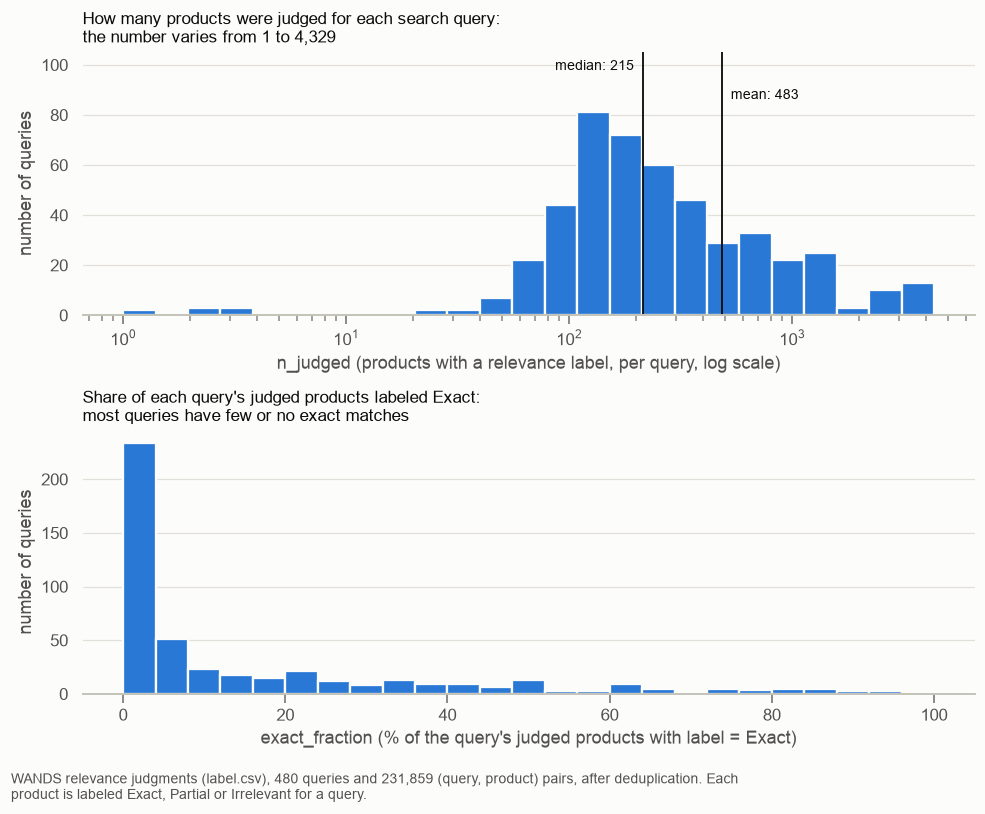

In [25]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7))

sns.histplot(query_profile["n_judged"], log_scale=True, bins=25, color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=top)
top.grid(axis="x", visible=False)
top.margins(y=0.3)
top.set_title("How many products were judged for each search query:\nthe number varies from 1 to 4,329")
top.set_xlabel("n_judged (products with a relevance label, per query, log scale)")
top.set_ylabel("number of queries")
plots.reference_line(top, query_profile["n_judged"].median(), f"median: {query_profile['n_judged'].median():.0f}", ha="right")
plots.reference_line(top, query_profile["n_judged"].mean(), f"mean: {query_profile['n_judged'].mean():.0f}", y_fraction=0.82)

sns.histplot(query_profile["exact_fraction"] * 100, bins=range(0, 104, 4), color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=bottom)
bottom.grid(axis="x", visible=False)
bottom.set_title("Share of each query's judged products labeled Exact:\nmost queries have few or no exact matches")
bottom.set_xlabel("exact_fraction (% of the query's judged products with label = Exact)")
bottom.set_ylabel("number of queries")

fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv), {len(query_profile)} queries and {len(labels):,} "
                       "(query, product) pairs, after deduplication. Each product is labeled Exact, Partial or "
                       "Irrelevant for a query.", width=115)
plt.show()

**Resultados**
- **`n_judged` varia muito:** de 1 a 4.329 produtos por query, com mediana 215 e média 483. Os 10% de queries com mais produtos julgados concentram 47,1% dos pares.
- **Cada query tem uma fração pequena do catalog julgada:** 0,50% na mediana (1,12% na média).
- **101 queries (21%) não têm nenhum Exact.** Entre as 479 queries que entram no split (Etapa 4.6), são 100.
- **1 query não tem nenhum produto relevante:** "drudge report", com um único produto, Irrelevant.
- **Algumas queries não parecem buscas por produto**, como "promo codes or discounts" e "drudge report".

**Suposições**
- **Queries com poucos produtos julgados medem o sistema tão bem quanto as outras**, já que cada query pesa o mesmo na nota final. Com 1 a 3 produtos julgados, isso é discutível: um único `label` decide a nota da query.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Excluir "drudge report" antes do split | decidida (`split.relevant_queries`) | mantê-la no split e fora das métricas que exigem produto relevante; contá-la com nota zero |
| As métricas que só contam Exact como relevante (Capped Recall@100 e MRR@10) usam só as 379 queries com Exact; NDCG@10 usa as 479 | decidida (`docs/EVALUATION.md`) | contar Exact e Partial como relevantes nessas métricas, cobrindo as 479 queries |
| Manter as 8 queries com menos de 10 produtos julgados | decidida | exigir um mínimo de produtos julgados; reportar a nota com e sem essas queries |

### 4.4 · Quantas vezes cada produto foi julgado?

Se poucos produtos concentrassem os labels, o modelo de ranking veria sempre os mesmos exemplos. Também medimos se o mesmo produto recebe `label` diferentes em queries diferentes.

In [26]:
labels_per_product = labels.groupby("product_id").size()
display(plots.table(labels_per_product.describe(percentiles=[0.5, 0.9, 0.99]).to_frame("labels_per_product").T,
                    f"Number of queries that judged each product ({len(labels_per_product):,} judged products)"))

product_label_counts = labels.groupby(["product_id", "label"]).size().unstack(fill_value=0)
plots.table(pd.Series({
    "products with at least one Exact": (product_label_counts["Exact"] > 0).sum(),
    "products with no Exact": (product_label_counts["Exact"] == 0).sum(),
    "products that are Irrelevant in every query that judged them": ((product_label_counts["Exact"] == 0) & (product_label_counts["Partial"] == 0)).sum(),
    "products that are Exact for one query and Irrelevant for another": ((product_label_counts["Exact"] > 0) & (product_label_counts["Irrelevant"] > 0)).sum(),
}, name="products"), "Labels received by each product across queries")

,count,mean,std,min,50%,90%,99%,max
labels_per_product,"42,986.0",5.4,4.4,1.0,4.0,12.0,18.0,45.0


,products
products with at least one Exact,"20,741"
products with no Exact,"22,245"
products that are Irrelevant in every query that judged them,983
products that are Exact for one query and Irrelevant for another,"13,605"


**Resultados**
- **Os labels não se concentram em poucos produtos:** a mediana é 4 queries por produto, e o máximo é 45.
- **A relevância depende da query, e não só do produto:** 13.605 produtos são Exact para uma query e Irrelevant para outra. Só 983 produtos são Irrelevant em todas as queries em que aparecem.

**Suposições**
- **Em produção chegam produtos novos, sem nenhum `label`.** Se o catalog fosse fixo, decorar produtos pelo `product_id` seria menos arriscado.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Não usar `product_id` como feature: o modelo precisa olhar a relação entre query e produto | decidida | usar `product_id` para capturar popularidade, com risco de o modelo decorar produtos; usar sinais de popularidade que não dependem do id, como `rating_count` |

### 4.5 · `product_class` concorda com `query_class`?

Para cada `label`, medimos a fração de pares em que algum single value de `product_class` do produto é igual à `query_class` da query (**class match**). Isso mostra o quanto a categoria separa os labels e se um filtro por categoria esconderia produtos relevantes.

É só uma análise: `query_class` não entra no sistema de busca.

In [27]:
class_match_pairs = (
    labels
    .merge(queries[["query_id", "query_class"]], on="query_id")
    .merge(products[["product_id", "product_class"]], on="product_id")
    .dropna(subset=["query_class", "product_class"])
)
class_match_pairs["class_match"] = [
    query_class in data.split_product_classes(product_class)
    for query_class, product_class in zip(class_match_pairs["query_class"], class_match_pairs["product_class"])
]

class_match_by_label = (
    class_match_pairs.groupby("label")["class_match"]
    .agg(pairs="size", class_match_pct=lambda s: s.mean() * 100)
    .loc[profiling.LABEL_NAMES]
)
display(plots.table(class_match_by_label, "Share of (query, product) pairs where product_class contains query_class, by label",
                    note=f"{len(class_match_pairs):,} pairs where both query_class and product_class are not null."))
exact_class_match_pairs = class_match_pairs[class_match_pairs["label"] == "Exact"]
print(f"Exact pairs whose product_class does not contain query_class: {(~exact_class_match_pairs['class_match']).sum():,}")

,pairs,class_match_pct
label,,
Exact,"23,571",74.0
Partial,"133,628",54.4
Irrelevant,"56,546",5.1


Exact pairs whose product_class does not contain query_class: 6,138


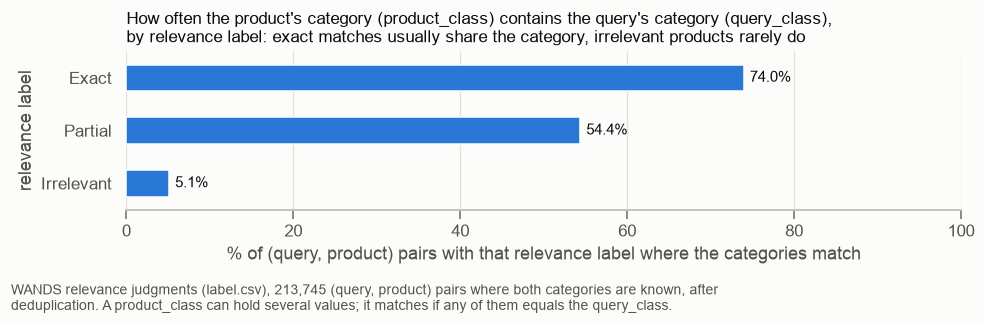

In [28]:
fig, ax = plt.subplots(figsize=(9, 2.6))
sns.barplot(x=class_match_by_label["class_match_pct"], y=profiling.LABEL_NAMES, color=plots.SERIES_1, saturation=1, width=0.5, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4, color=plots.PRIMARY_INK)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_title("How often the product's category (product_class) contains the query's category (query_class),\n"
             "by relevance label: exact matches usually share the category, irrelevant products rarely do")
ax.set_xlabel("% of (query, product) pairs with that relevance label where the categories match")
ax.set_ylabel("relevance label")
fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv), {len(class_match_pairs):,} (query, product) pairs where both "
                       "categories are known, after deduplication. A product_class can hold several values; "
                       "it matches if any of them equals the query_class.", width=110)
plt.show()

**Resultados**
- **A categoria é um sinal forte:** há class match em 74,0% dos pares Exact, 54,4% dos Partial e só 5,1% dos Irrelevant.
- **Mas não serve como filtro:** 26% dos pares Exact (6.138) não têm class match. Um filtro por categoria esconderia esses produtos, mesmo com a `query_class` certa em mãos.

**Suposições**
- **`query_class` representa o que um modelo preveria só com o texto da query.** Por isso esta análise é um limite superior para uma feature real, que teria de prever a categoria.

**Limitações**
- **A força do sinal pode estar inflada.** Segundo o artigo, parte dos candidatos foi escolhida para julgamento pelo `product_class` previsto para a query. O class match alto é, em parte, consequência de como os pares foram escolhidos, e esta medição não separa os dois efeitos.
- **Os 26% subestimam o problema do filtro.** O cálculo ignora pares sem `product_class`, que um filtro também esconderia.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Não filtrar por categoria; testar a semelhança entre a query e `product_class` / `category_hierarchy` como feature | proposta | filtrar pela classe prevista; boost (aumentar o score dos produtos da classe prevista, sem excluir os demais); usar a classe prevista como feature; não usar categoria |

#### Como usar `product_class` sem saber a categoria da query (proposta, não medida)

A busca não recebe `query_class`, mas `product_class` é uma coluna do produto: dá para comparar esse valor com o texto da query. Da forma mais simples à mais complexa:

1. **Indexed text:** `product_class` entra no texto em que o retrieval procura. A query "gray sofas" encontra um produto com `product_class` = `Sofas|Sectionals` porque os dois têm o token "sofas".
2. **Feature de semelhança no ranking:** por exemplo, a fração dos tokens da query presentes em `product_class`. Para "gray sofas" e `Sofas|Sectionals`, 1 de 2 tokens, ou seja, 0,5. A semelhança entre embeddings funciona de forma parecida e não exige tokens iguais.
3. **Prever a categoria da query** e usar a coincidência com o `product_class` do produto como feature. Há duas formas:
   - **Query classification:** um modelo aprende a prever a categoria a partir do texto da query, com `query_class` como resposta no treino. O limite são os poucos exemplos: 139 dos 188 valores de `query_class` têm menos de 3 queries (Etapa 3.3). Treinar com `product_name` e `product_class` daria mais exemplos, mas nomes de produtos não são escritos como buscas.
   - **Pseudo-relevance feedback:** tratar os primeiros resultados de um retrieval inicial como relevantes e usar o `product_class` mais comum entre eles como previsão, sem treinar classificador. O conceito vem da literatura de information retrieval; a aplicação a `product_class` é uma proposta nossa.

Em nenhuma das formas `query_class` entra na busca; na query classification, ela só é a resposta usada no treino.

| Escolha | Status | Alternativas |
|---|---|---|
| Começar pelas formas 1 e 2, que são simples e não dependem de previsão | proposta | testar a forma 3 na validation, se a error analysis mostrar que a categoria faz falta; não usar `product_class` |

### 4.6 · Como fazer o split das queries

O dataset não tem split oficial, então definimos o nosso. O protocolo formal está em `docs/EVALUATION.md`; aqui está o raciocínio.

**Regra 1 · Cada query fica inteira em um único set** (train, validation ou test set). Assim, validation e test set simulam queries que o sistema nunca viu. Se os produtos de uma query fossem divididos entre os sets, o modelo já teria visto a query no treino, e a nota sairia melhor do que na prática (data leakage).

**Regra 2 · Antes do split, saem as queries sem nenhum produto Exact ou Partial.** Sem produto relevante, Recall@K, MRR e NDCG@K valem 0 ou não existem para qualquer sistema. Só uma query sai: "drudge report" (Etapa 4.3).

**Regra 3 · Queries quase iguais formam um bloco** que vai inteiro para um set. Só há um bloco: "leather chair" e "leather chairs" (Etapa 3.4).

**Regra 4 · Stratification por duas variáveis.** A nota final é a média das notas por query, então queremos que os três sets tenham queries parecidas nessas variáveis. Como stratification exige grupos, cada variável é cortada em faixas, e as faixas das duas variáveis são cruzadas (4 × 3 = 12 grupos).

| Variável | Definição | O que mede | Por que estratificar | Faixas |
|---|---|---|---|---|
| `exact_share` | `Exact / (Exact + Partial)`, de 0 a 1 | Entre os produtos relevantes da query, a fração que é Exact. Não mede a dificuldade da query. | Com graded gain (Exact = 2, Partial = 1), uma query com muitos Exact pontua alto mais facilmente. Se um set tivesse, por acaso, mais queries assim, o sistema pontuaria mais nele sem ser melhor. Não medimos esse efeito neste notebook. Irrelevant fica fora porque seu número depende de quantos candidatos foram julgados. | exatamente 0; até 5%; de 5% a 25%; acima de 25% |
| `n_judged` | número de produtos com `label`, de 1 a 4.329 | O tamanho do conjunto julgado, incluindo Irrelevant. Também não mede dificuldade. | Acompanha o número de produtos relevantes (rank correlation de 0,880, mais abaixo), o que pode afetar métricas como Recall@K. Queremos uma mistura parecida de queries pequenas e grandes nos três sets. | 3 faixas com número parecido de queries |

**O que não usamos para estratificar**
- `query_class`: a maioria dos valores tem menos de 3 queries (Etapa 3.3), e a informação não existe em produção.
- A fração de Irrelevant: daria grupos pequenos demais.

**Parâmetros fixos:** proporção 60/20/20 e `seed = 87`, fixados antes de qualquer resultado de modelo. Com a seed fixa, o split é determinístico; não testamos outras seeds. O que importa é conferir, nas tabelas abaixo, se os três sets ficaram parecidos.

In [29]:
relevant_query_profile = split.relevant_queries(query_profile)
excluded_queries = query_profile.drop(relevant_query_profile.index)
print(f"queries with labels: {len(query_profile)} | with an Exact or Partial product: {len(relevant_query_profile)} "
      f"| excluded: {len(excluded_queries)}")
display(plots.table(queries.merge(excluded_queries, left_on="query_id", right_index=True)
                    [["query_id", "query", "Exact", "Partial", "Irrelevant", "n_judged"]].set_index("query_id"),
                    "Queries excluded before the split (no Exact and no Partial product)"))

stratification_groups = split.stratification_groups(relevant_query_profile)
query_bands = stratification_groups.str.split("|", expand=True).set_axis(["exact_share_band", "n_judged_band"], axis=1)
display(plots.table(pd.crosstab(query_bands["exact_share_band"], query_bands["n_judged_band"])
                    .reindex(index=split.EXACT_SHARE_NAMES, columns=split.N_JUDGED_NAMES),
                    "Queries per stratification group (exact_share band x n_judged band)",
                    note="exact_share bands: none = 0; up_to_5pct = up to 5%; 5_to_25pct = 5% to 25%; over_25pct = above 25%."))
plots.table(relevant_query_profile.groupby(query_bands["n_judged_band"])["n_judged"].agg(["min", "max", "count"])
            .reindex(split.N_JUDGED_NAMES).rename(columns={"count": "queries"}),
            "Range of n_judged in each n_judged band")

queries with labels: 480 | with an Exact or Partial product: 479 | excluded: 1


,query,Exact,Partial,Irrelevant,n_judged
query_id,,,,,
366,drudge report,0,0,1,1


n_judged_band,low,medium,high
exact_share_band,,,
none,49,26,25
up_to_5pct,31,41,53
5_to_25pct,34,35,42
over_25pct,48,55,40


,min,max,queries
n_judged_band,,,
low,1,149,162
medium,150,340,157
high,344,"4,329",160


In [30]:
query_split = split.split_queries(query_profile, queries)
SETS = list(split.SPLIT_FRACTIONS)
assert query_split.index.is_unique and set(query_split.index) == set(relevant_query_profile.index)

query_stats = relevant_query_profile.assign(
    exact_share=split.exact_share(relevant_query_profile),
    irrelevant_share=relevant_query_profile["Irrelevant"] / relevant_query_profile["n_judged"],
    split=query_split,
)
print(f"seed: {split.SPLIT_SEED} | fractions: {split.SPLIT_FRACTIONS}")
print(f"smallest stratification group: {stratification_groups.value_counts().min()} queries")
display(plots.table(query_stats.groupby("split").size().reindex(SETS).to_frame("queries").T, "Queries per set of the split"))

for column, definition in [
    ("n_judged", "number of products with a label for the query"),
    ("exact_share", "Exact / (Exact + Partial)"),
    ("irrelevant_share", "Irrelevant / n_judged"),
]:
    display(plots.table(query_stats.groupby("split")[column].describe(percentiles=[0.25, 0.5, 0.75])
                        .reindex(SETS)[["mean", "25%", "50%", "75%"]],
                        f"{column} per query, by set of the split", note=f"{column}: {definition}.", precision=3))

labels_by_set = labels.merge(query_split, left_on="query_id", right_index=True)
display(plots.table(pd.crosstab(labels_by_set["split"], labels_by_set["label"], normalize="index")
                    .reindex(index=SETS, columns=profiling.LABEL_NAMES),
                    "Share of (query, product) pairs per label, by set of the split",
                    note="Pairs are pooled across the queries of each set, so queries with more judged products weigh more.",
                    precision=3))

plots.table(near_duplicate_queries.set_index("query_id")[["query"]].assign(split=query_split),
            "Set of the split assigned to the near-duplicate queries")

seed: 87 | fractions: {'train': 0.6, 'validation': 0.2, 'test': 0.2}
smallest stratification group: 25 queries


split,train,validation,test
queries,287,97,95


,mean,25%,50%,75%
split,,,,
train,464.725,126.500,217.000,547.000
validation,498.155,122.000,218.000,504.000
test,528.011,115.000,211.000,464.000


,mean,25%,50%,75%
split,,,,
train,0.204,0.003,0.063,0.321
validation,0.226,0.005,0.065,0.301
test,0.221,0.005,0.081,0.382


,mean,25%,50%,75%
split,,,,
train,0.178,0.011,0.074,0.258
validation,0.226,0.020,0.088,0.364
test,0.204,0.016,0.078,0.333


label,Exact,Partial,Irrelevant
split,,,
train,0.112,0.649,0.239
validation,0.116,0.589,0.295
test,0.098,0.611,0.291


,query,split
query_id,,
26,leather chairs,validation
151,leather chair,validation


In [31]:
def rank_correlation(a: pd.Series, b: pd.Series) -> float:
    """Spearman correlation: the Pearson correlation of the ranks."""
    return a.rank().corr(b.rank())


relevant_exact_share = split.exact_share(relevant_query_profile)
display(plots.table(pd.Series({
    "n_judged vs Exact + Partial": rank_correlation(relevant_query_profile["n_judged"],
                                                    relevant_query_profile["Exact"] + relevant_query_profile["Partial"]),
    "n_judged vs Irrelevant": rank_correlation(relevant_query_profile["n_judged"], relevant_query_profile["Irrelevant"]),
    "n_judged vs exact_share": rank_correlation(relevant_query_profile["n_judged"], relevant_exact_share),
    "exact_share vs exact_fraction (Exact / n_judged)": rank_correlation(relevant_exact_share, relevant_query_profile["exact_fraction"]),
}, name="spearman_correlation"), f"Rank correlation between per-query label counts ({len(relevant_query_profile)} queries)",
    note="Spearman correlation: from -1 to 1, using only the order of the values; 0 means no relationship.", precision=3))
print(f"queries with 90% or more Irrelevant products: {(query_stats['irrelevant_share'] >= 0.9).sum()}")

train_products = set(labels_by_set.loc[labels_by_set["split"] == "train", "product_id"])
products_seen_in_train = []
for set_name in ["validation", "test"]:
    set_pairs = labels_by_set[labels_by_set["split"] == set_name]
    set_products = set_pairs["product_id"].drop_duplicates()
    products_seen_in_train.append({
        "set": set_name,
        "pairs_with_product_judged_in_train_pct": set_pairs["product_id"].isin(train_products).mean() * 100,
        "distinct_products": len(set_products),
        "distinct_products_not_judged_in_train": (~set_products.isin(train_products)).sum(),
    })
plots.table(pd.DataFrame(products_seen_in_train).set_index("set"),
            "Products of the validation and test sets that were also judged for a train query")

,spearman_correlation
n_judged vs Exact + Partial,0.880
n_judged vs Irrelevant,0.516
n_judged vs exact_share,-0.013
exact_share vs exact_fraction (Exact / n_judged),0.975


queries with 90% or more Irrelevant products: 8


,pairs_with_product_judged_in_train_pct,distinct_products,distinct_products_not_judged_in_train
set,,,
validation,94.7,"25,388","2,155"
test,92.7,"25,112","2,587"


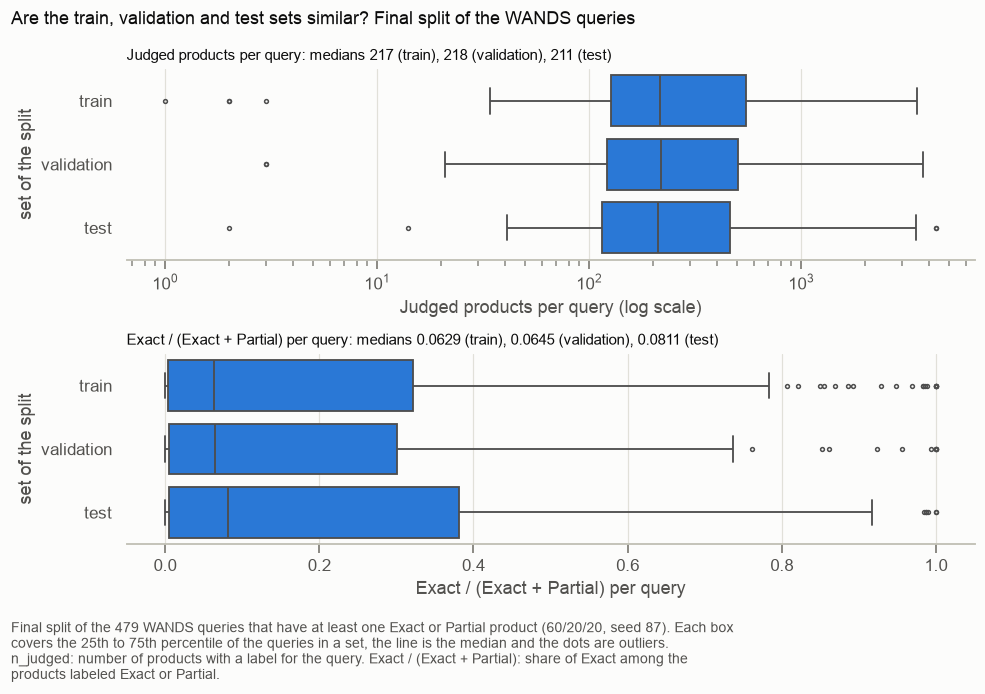

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6))
panels = [
    ("n_judged", "Judged products per query", True),
    ("exact_share", "Exact / (Exact + Partial) per query", False),
]
for ax, (column, axis_label, log_scale) in zip(axes, panels):
    sns.boxplot(data=query_stats, x=column, y="split", order=SETS, color=plots.SERIES_1, log_scale=log_scale,
                saturation=1, linewidth=1.2, fliersize=2.5, ax=ax)
    ax.set_xlabel(axis_label + (" (log scale)" if log_scale else ""))
    ax.set_ylabel("set of the split")
    medians = query_stats.groupby("split")[column].median().reindex(SETS)
    ax.set_title(f"{axis_label}: medians {medians.iloc[0]:.3g} (train), {medians.iloc[1]:.3g} (validation), {medians.iloc[2]:.3g} (test)",
                 fontsize=10)
fig.suptitle("Are the train, validation and test sets similar? Final split of the WANDS queries", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plots.add_caption(fig, f"Final split of the {len(query_stats)} WANDS queries that have at least one Exact or Partial product "
                       f"(60/20/20, seed {split.SPLIT_SEED}). Each box covers the 25th to 75th percentile of the queries in a set, "
                       "the line is the median and the dots are outliers. n_judged: number of products with a label for the query. "
                       "Exact / (Exact + Partial): share of Exact among the products labeled Exact or Partial.", width=115)
plt.show()

**Resultados**
- **Exclusão:** 1 das 480 queries sai antes do split: `query_id` 366, "drudge report", com um único par Irrelevant. Restam 479 queries.
- **Grupos de stratification:** os 12 grupos têm de 25 a 55 queries.
- **Tamanho dos sets:** 287 queries no train set, 97 no validation set e 95 no test set. Sem o bloco "leather chair" / "leather chairs", que foi para o validation set, seriam 287, 96 e 96.
- **`n_judged` ficou equilibrado:** medianas de 217 (train), 218 (validation) e 211 (test), com quartis parecidos.
- **`exact_share` ficou um pouco maior no test set:** medianas de 0,063 (train), 0,065 (validation) e 0,081 (test); 3º quartil de 0,321, 0,301 e 0,382.
- **Irrelevant:** por query, a mediana de `irrelevant_share` é parecida (0,074, 0,088 e 0,078). Contando pares, validation e test set têm mais Irrelevant (29,5% e 29,1%) do que o train set (23,9%). Não estratificamos por isso e não investigamos a causa.
- **Tamanho e composição são quase independentes:** a rank correlation de `n_judged` com `Exact + Partial` é 0,880, com `Irrelevant` é 0,516 e com `exact_share` é −0,013. `exact_share` e `exact_fraction` ordenam as queries quase igual (0,975).
- **8 queries têm 90% ou mais de produtos Irrelevant.**
- **Muitos produtos se repetem entre os sets:** 94,7% dos pares do validation set e 92,7% dos do test set têm um produto também julgado para alguma query do train set. Isso não é data leakage: a query é nova, e o modelo não usa `product_id` como feature (Etapa 4.4).

**Suposições**
- **Um set com mais queries de `exact_share` alto teria notas maiores só por isso.** É a razão de estratificar por `exact_share`. Não medimos esse efeito neste notebook; se ele não aparecer com o primeiro BM25 (medido só em train e validation set), a stratification pode ser revista antes de usar o test set.
- **Usar `label` para escolher o set de cada query não é data leakage**, porque o modelo não recebe essa informação. A escolha usa as respostas, mas só para equilibrar os sets.

**Limitações**
- Com cerca de 95 queries por set, diferenças pequenas entre os sets são esperadas por acaso. Não fizemos teste estatístico para saber se as diferenças acima são maiores do que isso.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Split por query | decidida | split por par (query, produto), descartado porque o modelo já teria visto a query no treino |
| Excluir antes do split as queries sem Exact nem Partial | decidida | mantê-las no split e tirá-las só das métricas, o que deixaria o conjunto de queries com duas definições |
| Stratification por `exact_share` e `n_judged` | decidida | sorteio simples, sem stratification; `exact_fraction` (inclui Irrelevant no denominador) no lugar de `exact_share`; `Exact + Partial` no lugar de `n_judged`; ordenar as queries pelo valor e distribuí-las sem faixas; usar só o texto da query, sem olhar `label` |
| 60/20/20 | decidida | 70/15/15, que dá mais queries ao treino, mas deixa o test set com cerca de 70 queries e a nota mais ruidosa; 80/10/10 |
| Um único split fixo, `seed = 87` | decidida | cross-validation por query sobre train e validation set juntos, mais estável e mais cara; o test set continuaria sendo usado uma única vez |
| Queries quase iguais em um bloco | decidida | tratá-las como independentes, arriscando ter uma no train set e outra no test set |

### 4.7 · As colunas de rating diferem entre Exact, Partial e Irrelevant?

A Etapa 2.1 descreveu `rating_count`, `average_rating` e `review_count` produto a produto. Aqui juntamos essas colunas a `labels` (depois da deduplication) para ver se os produtos Exact, Partial e Irrelevant têm ratings diferentes. Se não tiverem, as colunas dizem pouco sobre a relevância para a query.

Cada linha é um par (query, produto), então um produto julgado para muitas queries pesa mais. Para cada `label`, medimos:
1. A fração de pares cujo produto não tem rating (`rating_count` null).
2. Entre os pares cujo produto tem rating, a distribuição de `rating_count`, `average_rating` e `review_count`.

In [33]:
pair_ratings = labels.merge(products[["product_id", *RATING_COLUMNS]], on="product_id")
pair_ratings["has_ratings"] = pair_ratings["rating_count"].notna().astype(int)
rated_pairs = pair_ratings[pair_ratings["has_ratings"] == 1]

rating_presence_by_label = (
    pair_ratings.groupby("label")["has_ratings"]
    .agg(pairs="size", without_ratings_pct=lambda s: (1 - s.mean()) * 100)
    .loc[profiling.LABEL_NAMES]
)
display(plots.table(rating_presence_by_label, "Share of judged (query, product) pairs whose product has no ratings, by label",
                    note=f"{len(pair_ratings):,} pairs after deduplication."))

rating_stats_by_label = rated_pairs.groupby("label").agg(
    pairs=("label", "size"),
    rating_count_p25=("rating_count", lambda s: s.quantile(0.25)),
    rating_count_median=("rating_count", "median"),
    rating_count_p75=("rating_count", lambda s: s.quantile(0.75)),
    rating_count_mean=("rating_count", "mean"),
    review_count_median=("review_count", "median"),
    average_rating_mean=("average_rating", "mean"),
    average_rating_4_5_or_more_pct=("average_rating", lambda s: (s >= 4.5).mean() * 100),
).loc[profiling.LABEL_NAMES]
plots.table(rating_stats_by_label.T, "Rating columns of the judged products that have ratings, by label",
            note=f"{len(rated_pairs):,} pairs whose product has ratings. p25 and p75: first and third quartiles.", precision=2)

,pairs,without_ratings_pct
label,,
Exact,"25,470",19.1
Partial,"145,670",24.1
Irrelevant,"60,719",20.5


label,Exact,Partial,Irrelevant
pairs,"20,616.00","110,631.00","48,261.00"
rating_count_p25,9.00,9.00,8.00
rating_count_median,42.00,54.00,44.00
rating_count_p75,171.00,253.00,193.00
rating_count_mean,379.41,508.56,428.73
review_count_median,32.00,41.00,33.00
average_rating_mean,4.53,4.50,4.52
average_rating_4_5_or_more_pct,84.54,84.28,84.69


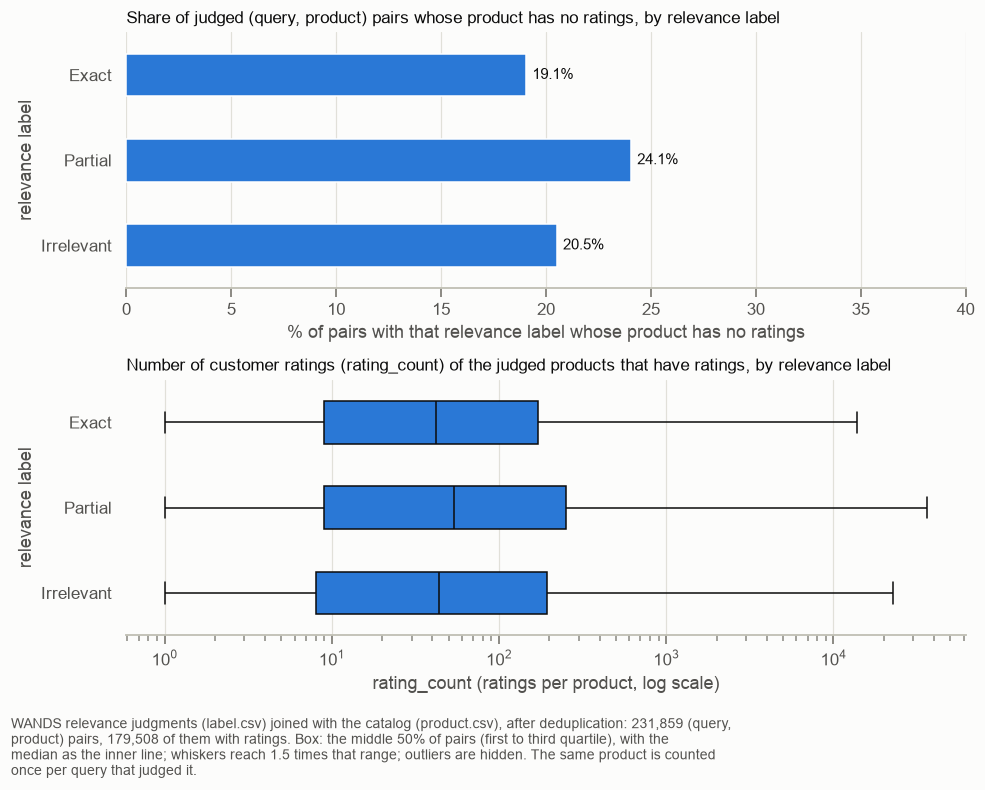

In [34]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.5))

sns.barplot(x=rating_presence_by_label["without_ratings_pct"], y=profiling.LABEL_NAMES, color=plots.SERIES_1, saturation=1, width=0.5, ax=top)
top.bar_label(top.containers[0], fmt="%.1f%%", padding=4, color=plots.PRIMARY_INK)
top.set_xlim(0, 40)
top.grid(axis="y", visible=False)
top.set_title("Share of judged (query, product) pairs whose product has no ratings, by relevance label")
top.set_xlabel("% of pairs with that relevance label whose product has no ratings")
top.set_ylabel("relevance label")

sns.boxplot(data=rated_pairs, x="rating_count", y="label", order=profiling.LABEL_NAMES, log_scale=True, showfliers=False,
            color=plots.SERIES_1, saturation=1, width=0.5, linecolor=plots.PRIMARY_INK, ax=bottom)
bottom.grid(axis="y", visible=False)
bottom.set_title("Number of customer ratings (rating_count) of the judged products that have ratings, by relevance label")
bottom.set_xlabel("rating_count (ratings per product, log scale)")
bottom.set_ylabel("relevance label")

fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv) joined with the catalog (product.csv), after deduplication: "
                       f"{len(pair_ratings):,} (query, product) pairs, {len(rated_pairs):,} of them with "
                       "ratings. Box: the middle 50% of pairs (first to third quartile), with the median as the inner "
                       "line; whiskers reach 1.5 times that range; outliers are hidden. The same product is counted "
                       "once per query that judged it.", width=115)
plt.show()

**Resultados**
- **`rating_count` quase não muda entre os labels:** mediana de 42 (Exact), 54 (Partial) e 44 (Irrelevant), com quartis sobrepostos (1º quartil de 8 ou 9 nos três; 3º quartil de 171 a 253).
- **`average_rating` não separa os labels:** média de 4,53, 4,50 e 4,52; a fração de pares com 4,5 estrelas ou mais vai de 84,3% a 84,7%.
- **A fração sem rating muda pouco:** 19,1% dos pares Exact, 24,1% dos Partial e 20,5% dos Irrelevant. A ordem não acompanha a relevância (Partial é o maior).
- **`rating_count` alto não indica relevância:** Partial tem a maior média (509), mas Exact tem a menor (379), abaixo de Irrelevant (429).

**Suposições**
- **Os ratings do catalog são os que os anotadores viram.** O dataset não tem datas; se os ratings mudaram depois do julgamento, a comparação mistura momentos diferentes.

**Limitações**
- **Pooling bias:** os pares foram escolhidos por sistemas de busca, e não sorteados (Etapa 5.1). A comparação descreve os produtos julgados, não o catalog.
- **A comparação mistura queries.** Produtos de uma query podem ter mais ratings que os de outra, e esse efeito aparece como diferença entre labels. A Etapa 4.8 compara dentro de cada query.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Manter `rating_count` (em log), `average_rating` e `review_count` como features fracas e decidir pela ablation na validation, em vez de assumir que ajudam | proposta | descartá-las já; usá-las só como desempate; usar só `has_ratings` |

### 4.8 · Dentro de cada query, as colunas de rating acompanham o `label`?

A Etapa 4.7 comparou todos os pares juntos. Isso mistura dois efeitos: os produtos de uma query podem ter mais ratings que os de outra (por exemplo, "sofa" recebe produtos muito avaliados por clientes), e essa diferença aparece entre labels mesmo que, dentro de cada query, os ratings não ajudem a ordenar. O ranking só compara produtos da mesma query, então a pergunta que importa é a de dentro da query.

**Termos**
- **Spearman correlation:** mede se duas variáveis crescem juntas, usando só a ordem dos valores. Vai de −1 a 1; 0 significa que uma não acompanha a outra. Calculamos uma por query, entre a ordem do `label` (Irrelevant = 0 < Partial = 1 < Exact = 2) e o valor da coluna. Em empates, cada valor recebe a posição média.
- **Bootstrap confidence interval:** sorteamos as queries com reposição e recalculamos a média das correlações, 2.000 vezes. O intervalo de 95% vai do percentil 2,5 ao 97,5 dessas médias. Se ele contém 0, não distinguimos a média de 0. Sorteamos queries, e não pares, porque pares da mesma query não são independentes.

**Filtro:** só entram queries com pelo menos 20 pares com valor conhecido e correlação definida (a correlação não existe se todos os pares da query têm o mesmo `label` ou o mesmo valor). `has_ratings` usa todos os pares, inclusive os de produtos sem rating.

In [35]:
BOOTSTRAP_SEED = 0
MIN_PAIRS_PER_QUERY = 20

pair_ratings["log10_rating_count"] = np.log10(pair_ratings["rating_count"])
WITHIN_QUERY_COLUMNS = ["log10_rating_count", "average_rating", "review_count", "has_ratings"]

within_query_correlations = {
    column: profiling.within_query_spearman(pair_ratings, column, min_pairs=MIN_PAIRS_PER_QUERY)
    for column in WITHIN_QUERY_COLUMNS
}
within_query_summary = []
for column, correlations in within_query_correlations.items():
    low, high = metrics.bootstrap_mean_ci(correlations, seed=BOOTSTRAP_SEED)
    within_query_summary.append({
        "column": column, "queries": len(correlations), "mean": correlations.mean(), "median": correlations.median(),
        "ci_low": low, "ci_high": high, "queries_positive_pct": (correlations > 0).mean() * 100,
        "queries_negative_pct": (correlations < 0).mean() * 100,
    })
within_query_summary = pd.DataFrame(within_query_summary).set_index("column")
display(plots.table(within_query_summary, "Spearman correlation between label order and each rating column, computed inside each query",
                    note=f"One correlation per query with at least {MIN_PAIRS_PER_QUERY} pairs with a known value. "
                         "ci_low and ci_high: 95% bootstrap confidence interval of the mean (2,000 resamples of the queries, "
                         f"seed {BOOTSTRAP_SEED}).", precision=3))
print(f"queries with at least {MIN_PAIRS_PER_QUERY} judged pairs: {(query_profile['n_judged'] >= MIN_PAIRS_PER_QUERY).sum()}")

,queries,mean,median,ci_low,ci_high,queries_positive_pct,queries_negative_pct
column,,,,,,,
log10_rating_count,449,0.012,0.018,-0.006,0.030,53.007,46.993
average_rating,449,0.001,-0.001,-0.012,0.014,47.884,50.557
review_count,449,0.011,0.022,-0.007,0.030,53.898,46.102
has_ratings,451,0.017,0.008,0.002,0.031,50.998,46.120


queries with at least 20 judged pairs: 471


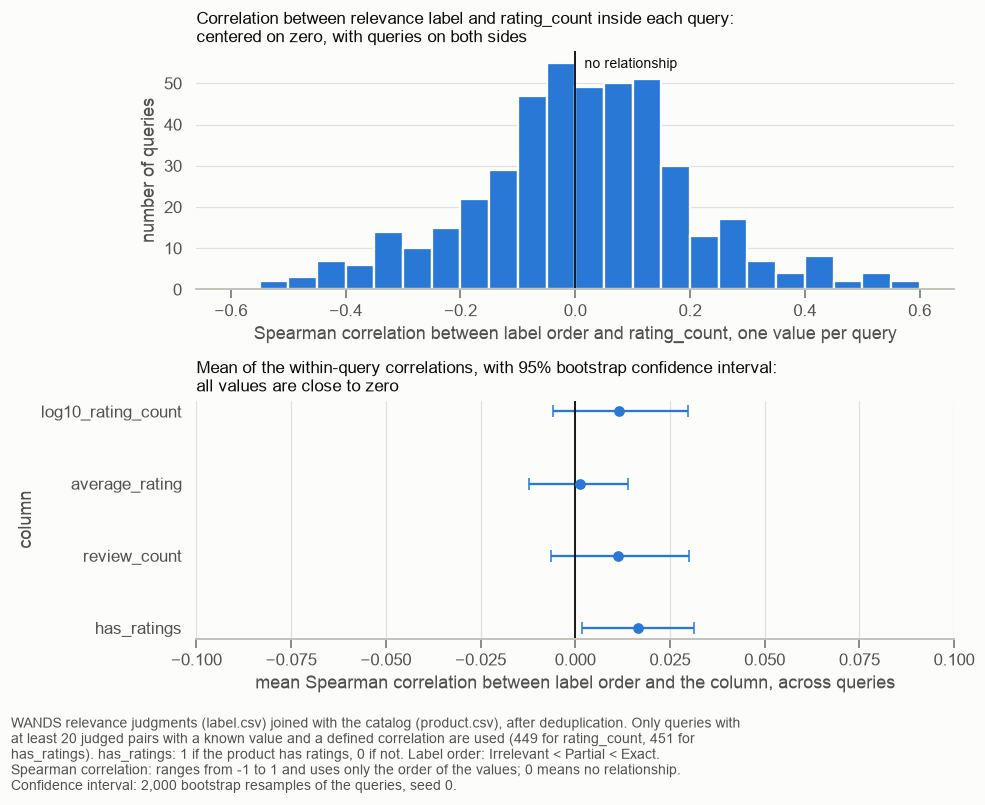

In [36]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.5))

sns.histplot(within_query_correlations["log10_rating_count"], bins=np.arange(-0.6, 0.65, 0.05), color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=top)
top.grid(axis="x", visible=False)
top.set_title("Correlation between relevance label and rating_count inside each query:\n"
              "centered on zero, with queries on both sides")
top.set_xlabel("Spearman correlation between label order and rating_count, one value per query")
top.set_ylabel("number of queries")
plots.reference_line(top, 0, "no relationship")

summary = within_query_summary.reset_index()
bottom.errorbar(summary["mean"], range(len(summary)), xerr=[summary["mean"] - summary["ci_low"], summary["ci_high"] - summary["mean"]],
                fmt="o", color=plots.SERIES_1, ecolor=plots.SERIES_1, capsize=4)
bottom.set_yticks(range(len(summary)), summary["column"])
bottom.invert_yaxis()
bottom.axvline(0, color=plots.PRIMARY_INK, linewidth=1.2)
bottom.grid(axis="y", visible=False)
bottom.set_xlim(-0.1, 0.1)
bottom.set_title("Mean of the within-query correlations, with 95% bootstrap confidence interval:\n"
                 "all values are close to zero")
bottom.set_xlabel("mean Spearman correlation between label order and the column, across queries")
bottom.set_ylabel("column")

fig.tight_layout()
plots.add_caption(fig, "WANDS relevance judgments (label.csv) joined with the catalog (product.csv), after deduplication. "
                       f"Only queries with at least {MIN_PAIRS_PER_QUERY} judged pairs with a known value and a defined correlation "
                       f"are used ({within_query_summary.loc['log10_rating_count', 'queries']} for rating_count, "
                       f"{within_query_summary.loc['has_ratings', 'queries']} for has_ratings). has_ratings: 1 if the product has ratings, 0 if not. "
                       "Label order: Irrelevant < Partial < Exact. Spearman correlation: ranges from -1 to 1 and uses only the order "
                       f"of the values; 0 means no relationship. Confidence interval: 2,000 bootstrap resamples of the queries, seed {BOOTSTRAP_SEED}.",
                  width=115)
plt.show()

**Resultados**
- **Dentro da query, as colunas de rating não acompanham o `label`.** Os intervalos de `log10_rating_count`, `average_rating` e `review_count` contêm 0. O de `has_ratings` fica logo acima de 0 ([0,002; 0,031]), com efeito minúsculo (média 0,017).
- **A direção muda de query para query:** a correlação de `rating_count` é positiva em 53,0% das queries e negativa em 47,0%.
- **Queries individuais variam muito:** as correlações de `rating_count` vão de cerca de −0,55 a 0,6; a média perto de zero vem de queries que se compensam. Não separamos quanto disso é ruído de queries com poucos pares.
- **A diferença da Etapa 4.7 some dentro da query:** as medianas de `rating_count` por `label` (42, 54 e 44) não se repetem dentro das queries. Uma explicação possível, não testada, é que a diferença vem de quais produtos cada query recebeu.

**Suposições**
- **As queries são independentes entre si**, como o bootstrap exige. Produtos repetidos em várias queries podem tornar o intervalo real um pouco mais largo.

**Limitações**
- A Spearman correlation só detecta relações monótonas e trata os labels como igualmente espaçados. Uma relação em U (produtos muito populares e muito raros mais relevantes) não apareceria.
- Queries com menos de 20 pares com valor ficam de fora: entram 449 das 471 queries com pelo menos 20 pares julgados, na análise de `rating_count`. As que saem podem ser diferentes.
- Cada coluna é medida sozinha. Um modelo pode usar `rating_count` combinado com outras features, o que esta análise não captura.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Não esperar ganho de `rating_count`, `average_rating` e `review_count` sozinhos, mas mantê-los (`rating_count` e `review_count` em log) e `has_ratings` na ablation, para confirmar na métrica final | proposta | descartar as três colunas já; usar só `has_ratings`; testar combinações com features de texto |
| Medir com Spearman correlation dentro da query | decidida, nesta análise | NDCG de um ranking só por `rating_count` contra um ranking aleatório; permutation test dos `label` dentro de cada query; regressão do `label` em `rating_count` com efeito fixo de query |

## Etapa 5 · Pontos que afetam a avaliação

### 5.1 · Pooling bias

**Termos**
- **Pooling:** a forma comum de montar labels de busca. Não dá para julgar 43 mil produtos para cada query, então os anotadores julgam só os candidatos que algum sistema de busca retornou.
- **Pooling bias:** o efeito colateral do pooling. Produtos que esses sistemas não encontraram ficam sem `label`, mesmo que sejam relevantes. Um sistema novo que encontre esses produtos é avaliado como se tivesse errado.
- **Token:** palavra do texto, depois de remover acentos, passar para minúsculas e separar em tudo que não é letra nem dígito (`profiling.simple_tokens`). Palavras repetidas contam uma vez.
- **Token overlap:** a fração dos tokens da query que aparecem no texto do produto. Para a query "gray sofa" e o produto "sofa bed", o overlap é 0,5.
- **Product text:** nesta seção, `product_name` + `product_class` + `category_hierarchy` (sem `product_description` nem `product_features`).

O [artigo do WANDS](https://easychair.org/publications/preprint/wm4R) confirma o pooling: os candidatos vieram de cliques e adições ao carrinho, do Solr (uma lexical search), de uma busca neural e do `product_class` previsto para a query. O dataset não informa de onde veio cada par. Por isso olhamos dois sinais indiretos:
1. Os produtos julgados têm mais token overlap com a query do que produtos sorteados do catalog?
2. Dos produtos cujo product text contém todos os tokens da query, quantos foram julgados para ela? Para encontrá-los, montamos um **inverted index**: para cada token, o conjunto de produtos que o contêm.

In [37]:
product_text = (
    products["product_name"].fillna("") + " "
    + products["product_class"].fillna("") + " "
    + products["category_hierarchy"].fillna("")
)
product_tokens = dict(zip(products["product_id"], product_text.map(profiling.simple_tokens)))
query_tokens = dict(zip(queries["query_id"], queries["query"].map(profiling.simple_tokens)))

pair_overlap = labels[["query_id", "product_id", "label"]].copy()
pair_overlap["overlap"] = [
    profiling.token_overlap(query_tokens[query_id], product_tokens[product_id])
    for query_id, product_id in zip(pair_overlap["query_id"], pair_overlap["product_id"])
]

N_RANDOM_PRODUCTS = 200
rng = np.random.default_rng(SAMPLE_SEED)
product_ids = products["product_id"].to_numpy()
random_overlap = pd.Series({
    query_id: np.mean([
        profiling.token_overlap(tokens, product_tokens[product_id])
        for product_id in rng.choice(product_ids, N_RANDOM_PRODUCTS, replace=False)
    ])
    for query_id, tokens in query_tokens.items()
})
judged_overlap = pair_overlap.groupby("query_id")["overlap"].mean()

display(plots.table(pd.Series({
    "products judged for the query": judged_overlap.median(),
    f"{N_RANDOM_PRODUCTS} random catalog products": random_overlap.median(),
}, name="median_of_mean_overlap"), "Token overlap with the query: judged products vs random products",
    note="Mean overlap over the products of each query, then the median across the 480 queries.", precision=3))

overlap_by_label = pair_overlap.groupby("label")["overlap"].agg(
    pairs="size",
    mean_overlap="mean",
    zero_overlap_pct=lambda s: (s == 0).mean() * 100,
).loc[profiling.LABEL_NAMES]
display(plots.table(overlap_by_label, "Token overlap between query and product text, by label",
                    note="zero_overlap_pct: % of pairs with no query token in the product text.", precision=3))

inverted_index = {}
for product_id, tokens in product_tokens.items():
    for token in tokens:
        inverted_index.setdefault(token, set()).add(product_id)

judged_products_by_query = labels.groupby("query_id")["product_id"].agg(set)
all_token_matches = []
for query_id, tokens in query_tokens.items():
    postings = [inverted_index.get(token, set()) for token in tokens]
    matching_products = set.intersection(*postings) if postings else set()
    all_token_matches.append({
        "query_id": query_id,
        "matching_products": len(matching_products),
        "matching_products_judged": len(matching_products & judged_products_by_query.get(query_id, set())),
    })
all_token_matches = pd.DataFrame(all_token_matches).set_index("query_id")
queries_with_matches = all_token_matches[all_token_matches["matching_products"] > 0]
judged_match_pct = queries_with_matches["matching_products_judged"] / queries_with_matches["matching_products"] * 100
print(f"% of matching products judged per query, median across queries: {judged_match_pct.median():.1f}%")

plots.table(pd.Series({
    "queries with at least one matching product": len(queries_with_matches),
    "matching products, summed over queries": queries_with_matches["matching_products"].sum(),
    "of those, judged for that query": queries_with_matches["matching_products_judged"].sum(),
    "queries where every matching product was judged": (judged_match_pct == 100).sum(),
}, name="count"), "Products whose product text contains every token of the query: how many were judged",
    note="A matching product contains all tokens of the query in product_name + product_class + category_hierarchy.")

,median_of_mean_overlap
products judged for the query,0.485
200 random catalog products,0.018


,pairs,mean_overlap,zero_overlap_pct
label,,,
Exact,"25,470",0.672,4.908
Partial,"145,670",0.491,2.732
Irrelevant,"60,719",0.424,11.545


% of matching products judged per query, median across queries: 100.0%


,count
queries with at least one matching product,233
"matching products, summed over queries","12,756"
"of those, judged for that query","10,539"
queries where every matching product was judged,193


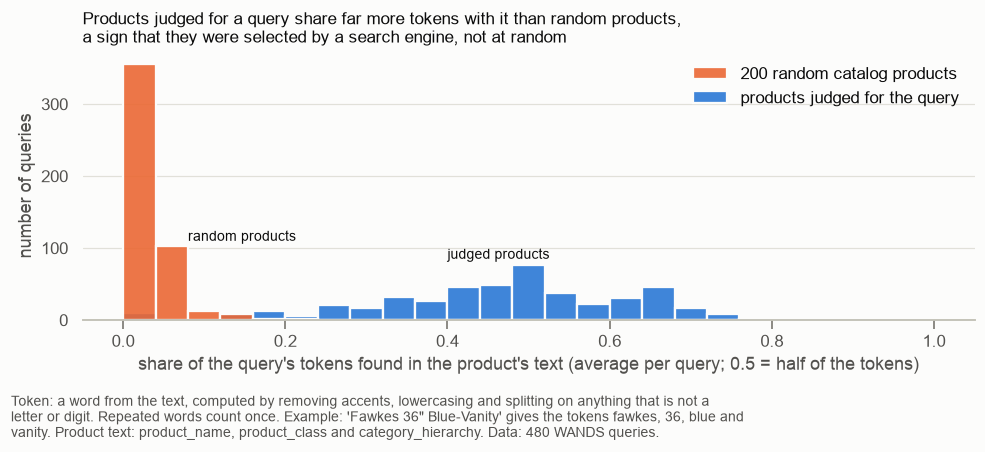

In [38]:
judged_series_name = "products judged for the query"
random_series_name = f"{N_RANDOM_PRODUCTS} random catalog products"
overlap_comparison = pd.concat([
    pd.DataFrame({"overlap": random_overlap, "products": random_series_name}),
    pd.DataFrame({"overlap": judged_overlap, "products": judged_series_name}),
])

fig, ax = plt.subplots(figsize=(9, 3.6))
sns.histplot(overlap_comparison, x="overlap", hue="products", bins=np.arange(0, 1.04, 0.04), multiple="layer", alpha=0.9,
             palette={random_series_name: plots.SERIES_2, judged_series_name: plots.SERIES_1},
             edgecolor=plots.SURFACE, linewidth=1.5, ax=ax)
ax.grid(axis="x", visible=False)
ax.set_title("Products judged for a query share far more tokens with it than random products,\n"
             "a sign that they were selected by a search engine, not at random")
ax.set_xlabel("share of the query's tokens found in the product's text (average per query; 0.5 = half of the tokens)")
ax.set_ylabel("number of queries")
ax.annotate("random products", xy=(0.08, 110), color=plots.PRIMARY_INK, fontsize=9)
ax.annotate("judged products", xy=(0.40, 85), color=plots.PRIMARY_INK, fontsize=9)
sns.move_legend(ax, "upper right", title=None)
fig.tight_layout()
plots.add_caption(fig, plots.TOKEN_DEFINITION + " Product text: product_name, product_class and category_hierarchy. "
                       f"Data: {len(queries)} WANDS queries.", width=115)
plt.show()

**Resultados**
- **Os produtos julgados não são uma amostra aleatória:** o token overlap médio com a query é 0,485, contra 0,018 de produtos sorteados (medianas entre as queries). Isso é coerente com o artigo: parte dos candidatos veio de sistemas de busca.
- **Quase todo produto com todos os tokens da query foi julgado:** há 12.756 casos assim, e 10.539 (83%) foram julgados. Em 193 das 233 queries que têm algum caso, todos foram julgados.
- **Mas o pooling não foi só por tokens:** 4,9% dos pares Exact, 2,7% dos Partial e 11,5% dos Irrelevant não têm nenhum token da query no product text.
- **Token overlap sozinho não ordena bem:** a média é 0,672 em Exact, 0,491 em Partial e 0,424 em Irrelevant. Os Irrelevant também têm muitos tokens da query.
- **247 das 480 queries não têm nenhum produto com todos os tokens** no product text.

**O que isso implica para a avaliação (nossa interpretação)**
- **Uma lexical search deve encontrar poucos produtos sem `label`,** porque os produtos com todos os tokens da query quase sempre foram julgados.
- **Uma semantic search pode ser prejudicada:** ela pode retornar produtos relevantes sem os tokens da query, que têm mais chance de estar sem `label`. Por isso a avaliação reporta judged@10 junto com a nota.
- **O ranking precisa de sinais além do token overlap**, já que os Irrelevant também têm muitos tokens da query.

**Suposições**
- **Token overlap é um indício de como os candidatos foram escolhidos.** O artigo confirma o pooling, mas não informa de onde veio cada par.

**Limitações**
- **O product text não tem `product_description` nem `product_features`.** Parte dos pares com overlap zero pode ter os tokens nessas colunas, e um retrieval que as use pode encontrar muito mais produtos sem `label`. Essa medição ainda não foi feita.
- Os tokens são comparados sem tratar plural e sem remover stopwords (palavras muito comuns, como "and" e "for").
- Os produtos sorteados representam o catalog do dataset, que, segundo o artigo, já é uma amostra de produtos ligados às queries, e não a loja inteira.
- Os anotadores viram também a imagem e a página do produto, que não estão no dataset. Alguns labels podem depender de informação que nenhum sistema aqui vê.

**Escolhas e alternativas**

**judged@10** é a fração dos 10 primeiros resultados de uma query que têm `label`.

| Escolha | Status | Alternativas |
|---|---|---|
| Produto sem `label` conta com gain 0 no NDCG@10, e reportamos judged@10 ao lado | decidida (`docs/EVALUATION.md`) | ignorar os produtos sem `label` no cálculo; usar métricas feitas para labels incompletos, como bpref; julgar à mão uma amostra dos resultados sem `label` |
| Medir o pooling bias com token overlap | decidida, nesta análise | BM25, que dá menos peso a tokens comuns; contar só tokens raros; medir com o primeiro BM25 quantos dos K primeiros resultados têm `label` |

### 5.2 · Text normalization

**Text normalization** é o tratamento aplicado ao texto antes de comparar query e produto, como passar para minúsculas e remover acentos. Query e produto precisam passar pelo mesmo tratamento; senão, palavras iguais não se encontram.

Perguntas:
1. O que já vem normalizado nos dados, e o que falta tratar?
2. Quais tokens das queries não existem em nenhum texto do catalog? Uma lexical search não consegue encontrá-los.

Contamos, em `product_name`, `product_description` e `query`, quantos valores têm:
- `has_uppercase`: alguma letra maiúscula;
- `spaced_comma`: vírgula cercada de espaços (` , `);
- `two_apostrophes`: dois apóstrofos seguidos (`''`), usados como símbolo de polegada;
- `double_quote`: aspas duplas (`"`), outro símbolo de polegada;
- `html_entity`: entidade HTML, como `&amp;`;
- `non_ascii`: algum caractere fora do ASCII, como `é`.

In [39]:
text_columns = {
    "product_name": products["product_name"],
    "product_description": products["product_description"].dropna(),
    "query": queries["query"],
}
formatting_counts = pd.DataFrame({
    column_name: {
        "values": len(values),
        "has_uppercase": values.str.contains(r"[A-Z]").sum(),
        "spaced_comma": values.str.contains(" , ", regex=False).sum(),
        "two_apostrophes": values.str.contains("''", regex=False).sum(),
        "double_quote": values.str.contains('"', regex=False).sum(),
        "html_entity": values.str.contains(r"&[a-z]+;").sum(),
        "non_ascii": values.str.contains(r"[^\x00-\x7f]").sum(),
    }
    for column_name, values in text_columns.items()
}).T
display(plots.table(formatting_counts, "Values with each formatting pattern, by text column",
                    note="product_description is counted only where it is not null."))

non_ascii_counts = Counter(
    character for text in pd.concat([products["product_name"], products["product_description"].dropna()])
    for character in text if ord(character) > 127
)
display(plots.table(pd.DataFrame(non_ascii_counts.most_common(10), columns=["character", "occurrences"]).set_index("character"),
                    "The 10 most common non-ASCII characters in product_name and product_description"))

catalog_vocabulary = set(inverted_index)
for text in products["product_description"].dropna():
    catalog_vocabulary |= profiling.simple_tokens(text)
print(f"catalog vocabulary (distinct tokens in product_name, product_class, category_hierarchy and product_description): "
      f"{len(catalog_vocabulary):,}")

tokens_missing_from_catalog = {query_id: sorted(tokens - catalog_vocabulary) for query_id, tokens in query_tokens.items()}
tokens_missing_from_catalog = {query_id: tokens for query_id, tokens in tokens_missing_from_catalog.items() if tokens}
plots.table(pd.DataFrame({
    "query": queries.set_index("query_id").loc[list(tokens_missing_from_catalog), "query"],
    "missing_tokens": pd.Series(tokens_missing_from_catalog),
}), f"The {len(tokens_missing_from_catalog)} queries with a token that appears in no catalog text",
    note="Catalog text: product_name, product_class, category_hierarchy and product_description (not product_features).")

,values,has_uppercase,spaced_comma,two_apostrophes,double_quote,html_entity,non_ascii
product_name,"42,994",0,935,"10,291",0,0,918
product_description,"36,986",0,"30,929","3,935",0,0,"6,882"
query,480,0,1,0,3,0,0


,occurrences
character,
’,"5,707"
é,"2,051"
–,"1,006"
”,999
®,691
™,487
°,378
—,364
“,301


catalog vocabulary (distinct tokens in product_name, product_class, category_hierarchy and product_description): 46,762


,query,missing_tokens
20,foutains with brick look,['foutains']
23,stoneford end tables white and wood,['stoneford']
62,7qt slow cooker,['7qt']
77,sancroft armchair,['sancroft']
78,dorel vanity,['dorel']
87,vlad modular sectional,['vlad']
90,filaret outdoor sofa,['filaret']
98,gracie oaks 62 oller 14 ceiling fan,['oller']
179,promo codes or discounts,"['discounts', 'promo']"
190,benjiamino faux leather power lift chair,['benjiamino']


**Resultados**
- **Já vem normalizado:** todo o texto está em minúsculas e sem entidades HTML.
- **Acentos precisam de tratamento:** as queries não têm caracteres fora do ASCII, mas 918 valores de `product_name` e 6.882 de `product_description` têm, como `é` (2.051 vezes). Sem tratamento, "decor" não encontra "décor". `profiling.simple_tokens`, usada nas Etapas 5.1 e 5.2, já remove acentos.
- **Polegadas se resolvem descartando a pontuação:** `36"` na query e `18 ''` em `product_name` (10.291 valores têm `''`) viram só o número. Isso perde a informação de que o número é uma medida.
- **36 queries (7,5%) têm tokens que não existem no catalog** (sem contar `product_features`). Lendo a lista, vemos typos ("foutains", "biycicle", "ligth"), nomes próprios ("stoneford", "filaret"), palavras grudadas ("roomtables", "7qt") e outras lojas ("lowes", "urban outfitters"). Essa classificação é nossa leitura.
- **Uma lexical search não encontra esses tokens.** É um argumento para comparar com uma semantic search ou hybrid search (que combina lexical e semantic search), como o desafio pede.

**Limitações**
- `product_features` não entra no catalog vocabulary, então alguns dos tokens ausentes podem existir nessa coluna.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Mesmo processamento em query e produto: remover acentos e descartar pontuação | proposta | manter os acentos; indexar as duas formas; aplicar stemming ou lemmatization para unir singular e plural |
| Reduzir medidas ao número | proposta | padronizar as unidades, de modo que `36"` e `36 ''` virem `36 inch`; manter a unidade como token separado |